# Large-Scale Metaparameter Tuning and Comparison via Multi-Task Bayesian Optimization

This notebook evaluates payoff-based Nash Equilibrium seeking across an ensemble of 100 strongly monotone quadratic games ($N=2, m=1$) with interior equilibria.
Using active task-selecting Multi-Task Bayesian Optimization (MTBO, Swersky et al. 2013), we tune both **Zero-Order Gradient Play (`ZOGrandientPlay`)** with one-point estimation and **Continuous-Time Extremum Seeking (`NESeeking`)**.

### Workflow Outline:
1. **Ensemble Generation:** Sample 100 strongly monotone quadratic games ensuring strictly interior Nash equilibria.
2. **Automated Representative Selection:** Programmatically select 5 diverse games (Extreme ill-conditioned, Well-behaved/isotropic, Narrow action bounds, Highly asymmetric coupling, Boundary-adjacent equilibrium).
3. **ZOGrandientPlay MTBO:** Multi-Task Bayesian Optimization ($n_{\text{init}}=100, n_{\text{bo}}=700$, strictly 1-point estimation, $N_{\text{iter}}=3000, K=50$) to discover game-specific $\theta_j^*$ and universal default $\theta_{\text{default}}^*$.
4. **ZOGrandientPlay Action Trajectory Visualizations:** For the 5 representative games, plot 2x2 dedicated subplots comparing action convergence under Game Optima vs. Default Optima (Actions only).
5. **NESeeking MTBO:** Multi-Task Bayesian Optimization ($n_{\text{init}}=100, n_{\text{bo}}=700$, $N_{\text{iter}}=3000, K=50$) to discover game-specific $\theta_j^*$ and universal default $\theta_{\text{default}}^*$.
6. **NESeeking Action Trajectory Visualizations:** For the 5 representative games, plot 2x2 dedicated subplots comparing action convergence under Game Optima vs. Default Optima (Actions only).
7. **Quantitative Comparative Report:** Comparative table of True NE vs. Game-Specific Optima vs. Default Optima, tunability metrics, and ensemble statistics across all 100 games.


## 0. Sanity Check: Frihauf Cournot Duopoly Metaparameter Optimization

This sanity check tunes both **ZOGrandientPlay** and **NESeeking** on the single 2-player Cournot duopoly price game from Frihauf et al. (2012).
- **Stopping Criterion:** `num_steps = 10000` for both optimization and trajectory simulations.
- **Optimization Metric:** Average Euclidean distance of **state history** (not actions) to the true Nash equilibrium $u^* = [43.3333, 36.6667]^T$ over all 10,001 iterations without smoothing window.
- **BO Configuration:** $n_{\text{init}} = 10$, $n_{\text{bo}} = 30$ (40 evaluations per algorithm).
- **Tuned Parameters:**
  - `ZOGrandientPlay`: $v \in [0.5, 10.0]$, $a \in [1.0, 150.0]$ (with $\varepsilon = 10^{-6}$ fixed).
  - `NESeeking`: Player-specific gains $k_{1,2} \in [0.1, 10.0]$, amplitudes $a_{1,2} \in [0.01, 0.2]$, frequencies $\omega_{1,2} \in [15.0, 35.0]$ (with $\Delta t = 0.001$, $\omega_h = 10.0$ fixed).
- **Regret Analysis:** Post-hoc computation of instantaneous and cumulative best-response regret ($R_1(t) = 5(u_1 - u_1^*(u_2))^2$, $R_2(t) = 5(u_2 - u_2^*(u_1))^2$) evaluating the economic exploration cost of the state-optimized parameters.
- **Plotting Y-Axis Limits:** States & Actions limited to $[0, 50]$, Payoffs limited to $[-1000, 1000]$ to remove transient outliers and highlight asymptotic convergence.
- **Artifacts:** Output CSVs, a 12-subplot trajectory plot, a 2-subplot regret dynamics plot, and execution timing summary saved to `data/00_sanity_check/`.


/home/bruno/Documents/PayoffBasedNEComparison/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


--- Starting ZOGrandientPlay MTBO (40 evaluations, 10,000 steps each) ---


/home/bruno/Documents/PayoffBasedNEComparison/.venv/lib/python3.14/site-packages/linear_operator/utils/interpolation.py:66: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  summing_matrix = torch.sparse_coo_tensor(


  [BO Step 1/30] Task 0: loss=1.32827, best_loss=1.00404 | max_ei: 0.461777
  [BO Step 25/30] Task 0: loss=0.98693, best_loss=0.92604 | max_ei: 0.001530
  [BO Step 30/30] Task 0: loss=1.75082, best_loss=0.80640 | max_ei: 0.000077
ZOGrandientPlay Best Parameters: {'epsilon': 1e-06, 'v': 9.991710752248764, 'a': 45.358901232481, 'game_id': 'game_0', 'is_default': False, 'objective_value': 0.8064010525413333}

--- Starting NESeeking MTBO (40 evaluations, 10,000 steps each) ---
  [BO Step 1/30] Task 0: loss=4.86116, best_loss=1.41786 | max_ei: 75.301602
  [BO Step 25/30] Task 0: loss=7.33544, best_loss=1.05911 | max_ei: 15.549298
  [BO Step 30/30] Task 0: loss=5.37021, best_loss=1.05911 | max_ei: 15.405534
NESeeking Best Parameters: {'dt': 0.001, 'omega_h[0]': 10.0, 'omega_h[1]': 10.0, 'k[0,0]': 5.067257654666901, 'k[1,0]': 0.4967502117156982, 'a[0,0]': 0.1271660566329956, 'a[1,0]': 0.08116431027650833, 'omega[0,0]': 15.158113334327936, 'omega[1,0]': 21.446309089660645, 'game_id': 'game_0',

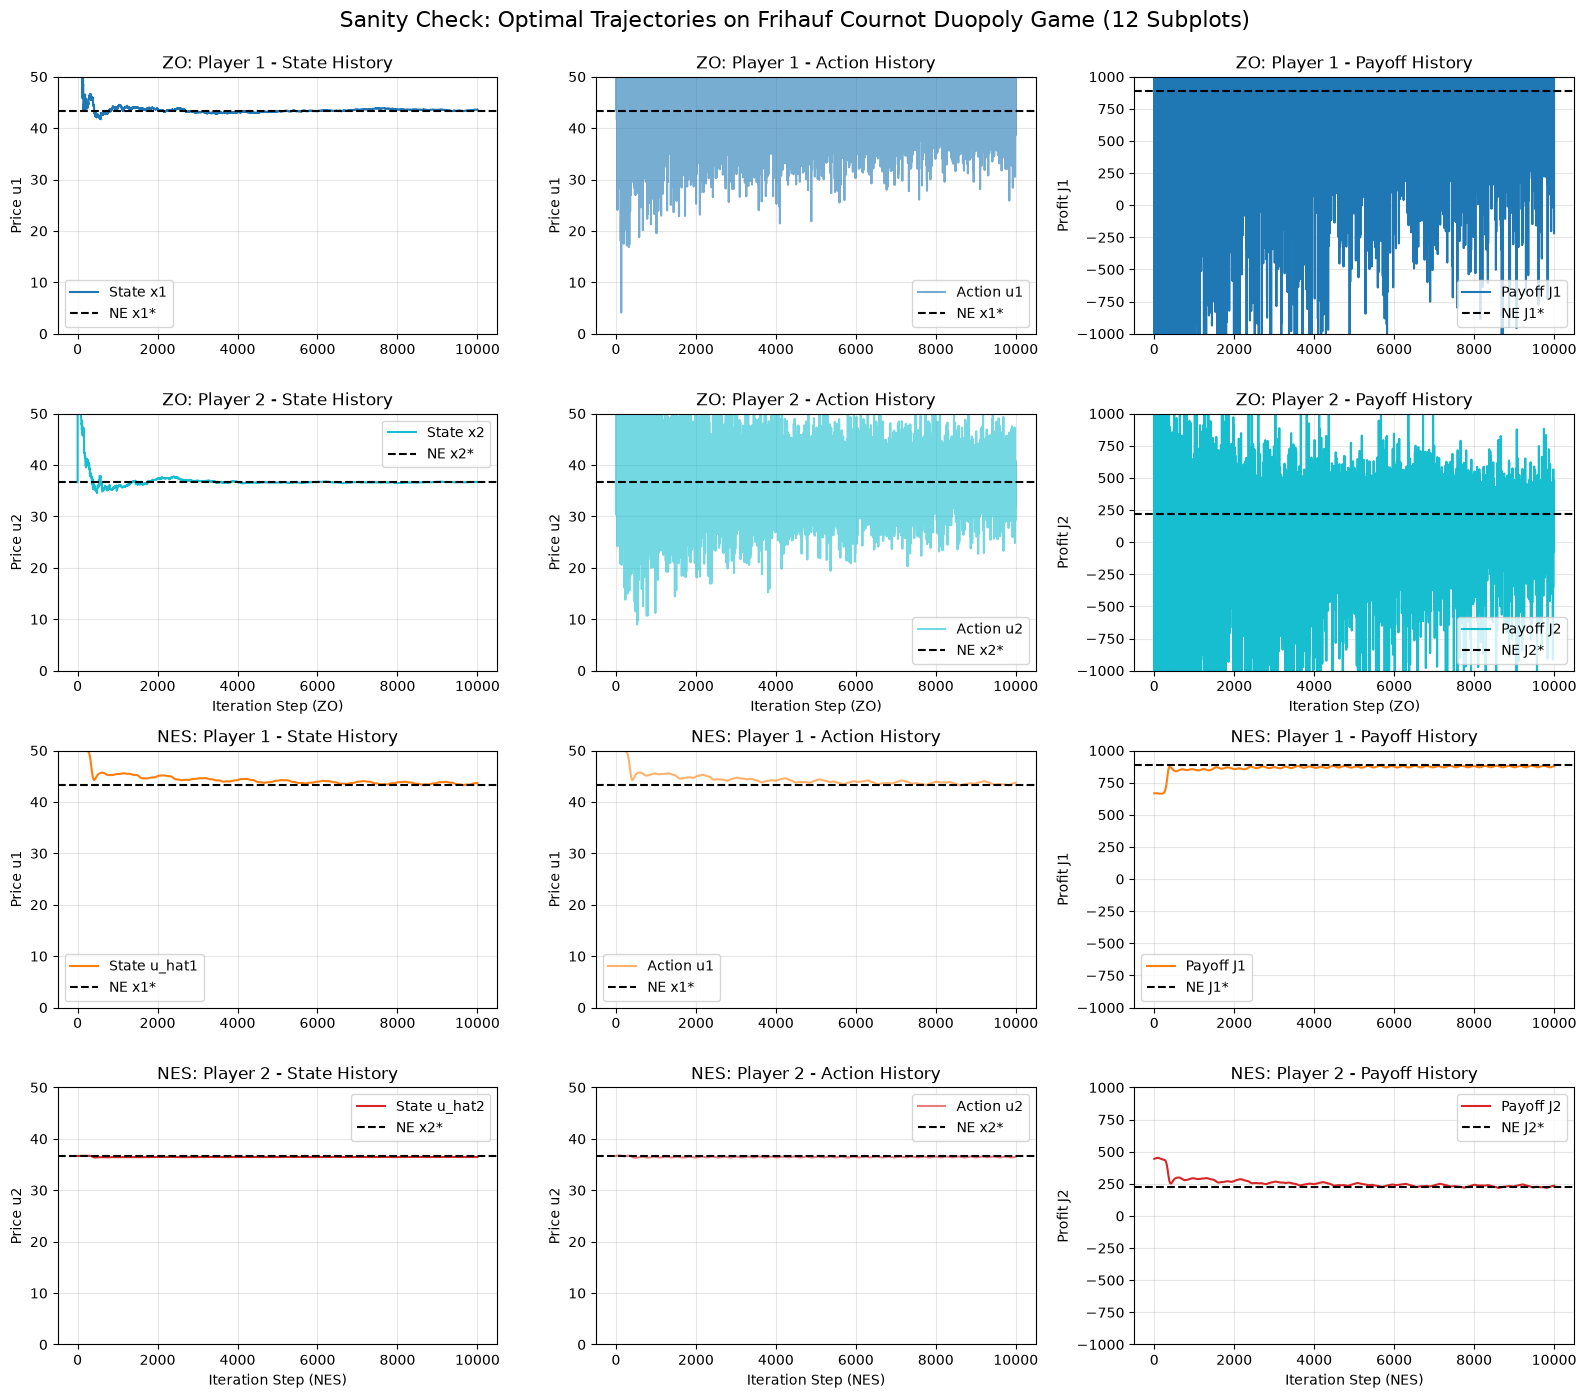

Sanity check regret plot saved to: data/00_sanity_check/cumulative_regret.png


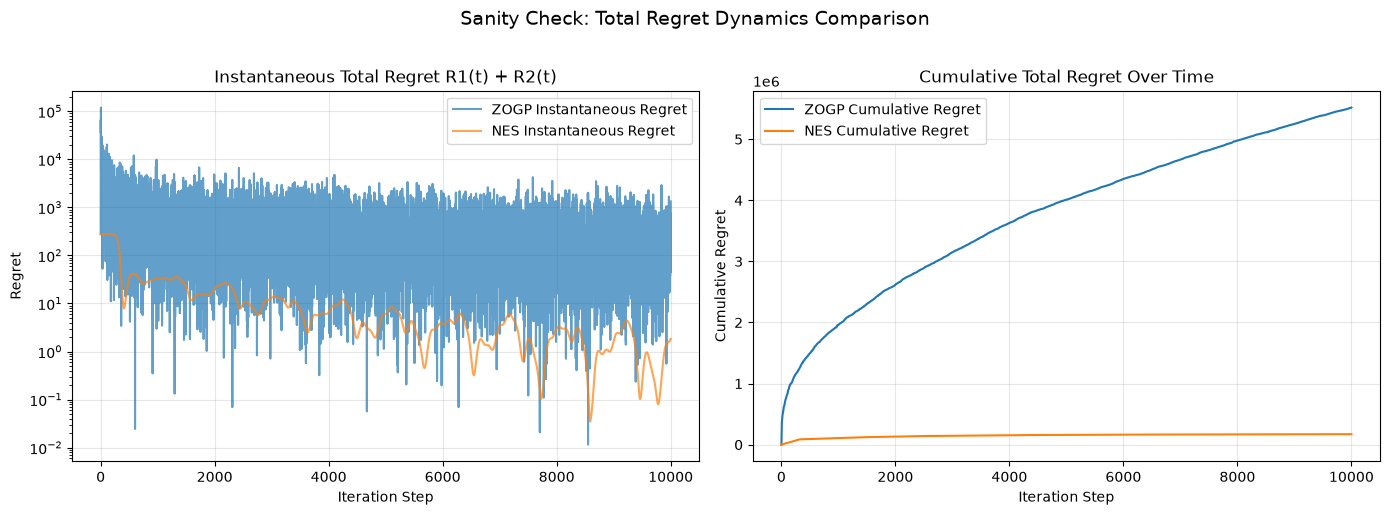

SANITY CHECK SUMMARY
Nash Equilibrium Reference: u* = [43.3333, 36.6667]
Optimal Payoffs Reference:  J* = [888.8889, 222.2222]
----------------------------------------------------------------------
ZOGrandientPlay:
  Best Parameters:     {'epsilon': 1e-06, 'v': 9.991710752248764, 'a': 45.358901232481, 'game_id': 'game_0', 'is_default': False, 'objective_value': 0.8064010525413333}
  Optimization Loss:   0.8064 (Mean State Dist to NE)
  Simulation Time:     0.24 seconds (10001 steps)
  Final State:         u_hat = [43.6151, 36.6999]
  Final Error:         ||u_hat - u*|| = 0.2837
  Sim Total Regret:    5517291.2958 (Mean per step: 551.6740)
----------------------------------------------------------------------
NESeeking:
  Best Parameters:     {'dt': 0.001, 'omega_h[0]': 10.0, 'omega_h[1]': 10.0, 'k[0,0]': 5.067257654666901, 'k[1,0]': 0.4967502117156982, 'a[0,0]': 0.1271660566329956, 'a[1,0]': 0.08116431027650833, 'omega[0,0]': 15.158113334327936, 'omega[1,0]': 21.446309089660645, 'game_

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

from payoffnash import (
    EstimateHistory,
    MetaParamOptimization,
    NESeeking,
    QuadraticGame,
    ZOGrandientPlay,
)

# 1. Output directory for sanity check artifacts
sanity_dir = "data/00_sanity_check"
os.makedirs(sanity_dir, exist_ok=True)

# 2. Define the exact Cournot duopoly game from Frihauf et al. / estimator main functions
N = 2
action_sets = [[(0.0, 300.0)], [(0.0, 300.0)]]
Sd, p, m1, m2 = 100.0, 0.2, 30.0, 30.0

def J1(u1, u2):
    s1 = Sd - (u1 - u2) / p
    return float(s1 * (u1 - m1))

def J2(u1, u2):
    s2 = (u1 - u2) / p
    return float(s2 * (u2 - m2))

H = np.array([[-10.0, 5.0], [5.0, -10.0]], dtype=float)
d = np.array([250.0, 150.0], dtype=float)
c = np.array([-3000.0, 0.0], dtype=float)
u_star = np.array([130.0 / 3.0, 110.0 / 3.0], dtype=float)
opt_payoffs = [8000.0 / 9.0, 2000.0 / 9.0]

cournot_game = QuadraticGame(
    N=N,
    action_sets=action_sets,
    payoff_functions=[J1, J2],
    H=H,
    d=d,
    c=c,
    nash_equilibrium=u_star,
    optimal_payoffs=opt_payoffs,
)

# Initial action profile: Interior starting point from Frihauf et al. (2012)
initial_actions = np.array([[50.0], [36.6667]], dtype=float)

# 3. Cost function: Mean distance of state history to true Nash equilibrium over all steps
def state_distance_cost(game: QuadraticGame, history: EstimateHistory) -> float:
    x_star = game.nash_equilibrium.ravel()
    dists = np.linalg.norm(history.state_history - x_star, axis=-1)
    return float(np.mean(dists))

# 4. ZOGrandientPlay MTBO (v, a)
zo_search_space = {
    "v": (0.5, 10.0),
    "a": (1.0, 150.0),
}
zo_fixed_params = {
    "epsilon": 1e-6,
}

print("--- Starting ZOGrandientPlay MTBO (40 evaluations, 10,000 steps each) ---")
zo_opt = MetaParamOptimization(
    game_ensemble=[cournot_game],
    search_space=zo_search_space,
    algorithm_class=ZOGrandientPlay,
    cost_function=state_distance_cost,
    output_path=os.path.join(sanity_dir, "zo_cournot_results.csv"),
    num_steps=10000,
    n_init=10,
    max_bo_steps=30,
    eps_ei=1e-4,
    seed=42,
    fixed_params=zo_fixed_params,
    initial_actions=initial_actions,
)
zo_results = zo_opt.run_optimization_loop()
zo_best_theta = zo_opt.best_thetas[0]
print(f"ZOGrandientPlay Best Parameters: {zo_results[0]}\n")

# 5. NESeeking MTBO (k, a, omega for both players)
ne_search_space = {
    "k[0,0]": (0.1, 10.0),
    "k[1,0]": (0.1, 10.0),
    "a[0,0]": (0.01, 0.2),
    "a[1,0]": (0.01, 0.2),
    "omega[0,0]": (15.0, 35.0),
    "omega[1,0]": (15.0, 35.0),
}
ne_fixed_params = {
    "dt": 0.001,
    "omega_h": np.array([10.0, 10.0]),
}

print("--- Starting NESeeking MTBO (40 evaluations, 10,000 steps each) ---")
ne_opt = MetaParamOptimization(
    game_ensemble=[cournot_game],
    search_space=ne_search_space,
    algorithm_class=NESeeking,
    cost_function=state_distance_cost,
    output_path=os.path.join(sanity_dir, "ne_cournot_results.csv"),
    num_steps=10000,
    n_init=10,
    max_bo_steps=30,
    eps_ei=1e-4,
    seed=42,
    fixed_params=ne_fixed_params,
    initial_actions=initial_actions,
)
ne_results = ne_opt.run_optimization_loop()
ne_best_theta = ne_opt.best_thetas[0]
print(f"NESeeking Best Parameters: {ne_results[0]}\n")

# 6. Simulate optimal trajectories (num_steps = 10000)
print("--- Simulating optimal trajectories (num_steps = 10000) ---")
zo_best_estimator = zo_opt.build_estimator(zo_best_theta, cournot_game)
ne_best_estimator = ne_opt.build_estimator(ne_best_theta, cournot_game)

t0_zo = time.time()
zo_history = zo_best_estimator.estimate(initial_actions, num_steps=10000)
zo_sim_time = time.time() - t0_zo

t0_ne = time.time()
ne_history = ne_best_estimator.estimate(initial_actions, num_steps=10000)
ne_sim_time = time.time() - t0_ne

# 7. Regret Analysis: Compute instantaneous and cumulative regret profiles
zo_u1 = zo_history.action_history[:, 0]
zo_u2 = zo_history.action_history[:, 1]
zo_r1 = 5.0 * (zo_u1 - (25.0 + 0.5 * zo_u2)) ** 2
zo_r2 = 5.0 * (zo_u2 - (15.0 + 0.5 * zo_u1)) ** 2
zo_tot_regret = zo_r1 + zo_r2
zo_cum_regret = np.cumsum(zo_tot_regret)

ne_u1 = ne_history.action_history[:, 0]
ne_u2 = ne_history.action_history[:, 1]
ne_r1 = 5.0 * (ne_u1 - (25.0 + 0.5 * ne_u2)) ** 2
ne_r2 = 5.0 * (ne_u2 - (15.0 + 0.5 * ne_u1)) ** 2
ne_tot_regret = ne_r1 + ne_r2
ne_cum_regret = np.cumsum(ne_tot_regret)

# 8. Plot 12 Subplots: State, Action, Payoff for both players and both algorithms
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
steps_zo = np.arange(len(zo_history.state_history))
steps_ne = np.arange(len(ne_history.state_history))

# Share x-axis within ZO (rows 0, 1) and within NES (rows 2, 3)
for col in range(3):
    axes[0, col].sharex(axes[1, col])
    axes[2, col].sharex(axes[3, col])

# Row 0: ZO - Player 1
axes[0, 0].plot(steps_zo, zo_history.state_history[:, 0], color="tab:blue", label="State x1")
axes[0, 0].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[0, 0].set_title("ZO: Player 1 - State History")
axes[0, 0].set_ylabel("Price u1")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(steps_zo, zo_history.action_history[:, 0], color="tab:blue", alpha=0.6, label="Action u1")
axes[0, 1].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[0, 1].set_title("ZO: Player 1 - Action History")
axes[0, 1].set_ylabel("Price u1")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].plot(steps_zo, zo_history.payoff_history[:, 0], color="tab:blue", label="Payoff J1")
axes[0, 2].axhline(opt_payoffs[0], color="black", linestyle="--", label="NE J1*")
axes[0, 2].set_title("ZO: Player 1 - Payoff History")
axes[0, 2].set_ylabel("Profit J1")
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# Row 1: ZO - Player 2
axes[1, 0].plot(steps_zo, zo_history.state_history[:, 1], color="tab:cyan", label="State x2")
axes[1, 0].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[1, 0].set_title("ZO: Player 2 - State History")
axes[1, 0].set_xlabel("Iteration Step (ZO)")
axes[1, 0].set_ylabel("Price u2")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(steps_zo, zo_history.action_history[:, 1], color="tab:cyan", alpha=0.6, label="Action u2")
axes[1, 1].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[1, 1].set_title("ZO: Player 2 - Action History")
axes[1, 1].set_xlabel("Iteration Step (ZO)")
axes[1, 1].set_ylabel("Price u2")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(steps_zo, zo_history.payoff_history[:, 1], color="tab:cyan", label="Payoff J2")
axes[1, 2].axhline(opt_payoffs[1], color="black", linestyle="--", label="NE J2*")
axes[1, 2].set_title("ZO: Player 2 - Payoff History")
axes[1, 2].set_xlabel("Iteration Step (ZO)")
axes[1, 2].set_ylabel("Profit J2")
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

# Row 2: NES - Player 1
axes[2, 0].plot(steps_ne, ne_history.state_history[:, 0], color="tab:orange", label="State u_hat1")
axes[2, 0].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[2, 0].set_title("NES: Player 1 - State History")
axes[2, 0].set_ylabel("Price u1")
axes[2, 0].legend()
axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(steps_ne, ne_history.action_history[:, 0], color="tab:orange", alpha=0.6, label="Action u1")
axes[2, 1].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[2, 1].set_title("NES: Player 1 - Action History")
axes[2, 1].set_ylabel("Price u1")
axes[2, 1].legend()
axes[2, 1].grid(True, alpha=0.3)

axes[2, 2].plot(steps_ne, ne_history.payoff_history[:, 0], color="tab:orange", label="Payoff J1")
axes[2, 2].axhline(opt_payoffs[0], color="black", linestyle="--", label="NE J1*")
axes[2, 2].set_title("NES: Player 1 - Payoff History")
axes[2, 2].set_ylabel("Profit J1")
axes[2, 2].legend()
axes[2, 2].grid(True, alpha=0.3)

# Row 3: NES - Player 2
axes[3, 0].plot(steps_ne, ne_history.state_history[:, 1], color="tab:red", label="State u_hat2")
axes[3, 0].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[3, 0].set_title("NES: Player 2 - State History")
axes[3, 0].set_xlabel("Iteration Step (NES)")
axes[3, 0].set_ylabel("Price u2")
axes[3, 0].legend()
axes[3, 0].grid(True, alpha=0.3)

axes[3, 1].plot(steps_ne, ne_history.action_history[:, 1], color="tab:red", alpha=0.6, label="Action u2")
axes[3, 1].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[3, 1].set_title("NES: Player 2 - Action History")
axes[3, 1].set_xlabel("Iteration Step (NES)")
axes[3, 1].set_ylabel("Price u2")
axes[3, 1].legend()
axes[3, 1].grid(True, alpha=0.3)

axes[3, 2].plot(steps_ne, ne_history.payoff_history[:, 1], color="tab:red", label="Payoff J2")
axes[3, 2].axhline(opt_payoffs[1], color="black", linestyle="--", label="NE J2*")
axes[3, 2].set_title("NES: Player 2 - Payoff History")
axes[3, 2].set_xlabel("Iteration Step (NES)")
axes[3, 2].set_ylabel("Profit J2")
axes[3, 2].legend()
axes[3, 2].grid(True, alpha=0.3)

# Apply y-axis limits to prevent initial outliers from masking convergence:
# [0, 50] for actions and states (columns 0 and 1)
# [-1000, 1000] for payoffs (column 2)
for r in range(4):
    axes[r, 0].set_ylim(0, 50)
    axes[r, 1].set_ylim(0, 50)
    axes[r, 2].set_ylim(-1000, 1000)

plt.suptitle("Sanity Check: Optimal Trajectories on Frihauf Cournot Duopoly Game (12 Subplots)", fontsize=16, y=0.995)
plt.tight_layout()
traj_plot_path = os.path.join(sanity_dir, "sanity_check_trajectories.png")
plt.savefig(traj_plot_path, dpi=300, bbox_inches="tight")
print(f"Sanity check trajectory plot saved to: {traj_plot_path}")
plt.show()

# 9. Plot Regret Trajectories: Instantaneous & Cumulative Regret
fig, (ax_inst, ax_cum) = plt.subplots(1, 2, figsize=(14, 5))

ax_inst.plot(steps_zo, zo_tot_regret, color="tab:blue", alpha=0.7, label="ZOGP Instantaneous Regret")
ax_inst.plot(steps_ne, ne_tot_regret, color="tab:orange", alpha=0.7, label="NES Instantaneous Regret")
ax_inst.set_title("Instantaneous Total Regret R1(t) + R2(t)")
ax_inst.set_xlabel("Iteration Step")
ax_inst.set_ylabel("Regret")
ax_inst.set_yscale("log")
ax_inst.grid(True, alpha=0.3)
ax_inst.legend()

ax_cum.plot(steps_zo, zo_cum_regret, color="tab:blue", lw=1.5, label="ZOGP Cumulative Regret")
ax_cum.plot(steps_ne, ne_cum_regret, color="tab:orange", lw=1.5, label="NES Cumulative Regret")
ax_cum.set_title("Cumulative Total Regret Over Time")
ax_cum.set_xlabel("Iteration Step")
ax_cum.set_ylabel("Cumulative Regret")
ax_cum.grid(True, alpha=0.3)
ax_cum.legend()

plt.suptitle("Sanity Check: Total Regret Dynamics Comparison", fontsize=14, y=1.02)
plt.tight_layout()
regret_plot_path = os.path.join(sanity_dir, "cumulative_regret.png")
plt.savefig(regret_plot_path, dpi=300, bbox_inches="tight")
print(f"Sanity check regret plot saved to: {regret_plot_path}")
plt.show()

# 10. Print comprehensive summary
print("=" * 70)
print("SANITY CHECK SUMMARY")
print("=" * 70)
print(f"Nash Equilibrium Reference: u* = [{u_star[0]:.4f}, {u_star[1]:.4f}]")
print(f"Optimal Payoffs Reference:  J* = [{opt_payoffs[0]:.4f}, {opt_payoffs[1]:.4f}]")
print("-" * 70)
print("ZOGrandientPlay:")
print(f"  Best Parameters:     {zo_results[0]}")
print(f"  Optimization Loss:   {zo_results[0]['objective_value']:.4f} (Mean State Dist to NE)")
print(f"  Simulation Time:     {zo_sim_time:.2f} seconds ({len(zo_history.state_history)} steps)")
print(f"  Final State:         u_hat = [{zo_history.state_history[-1][0]:.4f}, {zo_history.state_history[-1][1]:.4f}]")
print(f"  Final Error:         ||u_hat - u*|| = {np.linalg.norm(zo_history.state_history[-1] - u_star):.4f}")
print(f"  Sim Total Regret:    {zo_cum_regret[-1]:.4f} (Mean per step: {np.mean(zo_tot_regret):.4f})")
print("-" * 70)
print("NESeeking:")
print(f"  Best Parameters:     {ne_results[0]}")
print(f"  Optimization Loss:   {ne_results[0]['objective_value']:.4f} (Mean State Dist to NE)")
print(f"  Simulation Time:     {ne_sim_time:.2f} seconds ({len(ne_history.state_history)} steps)")
print(f"  Final State:         u_hat = [{ne_history.state_history[-1][0]:.4f}, {ne_history.state_history[-1][1]:.4f}]")
print(f"  Final Error:         ||u_hat - u*|| = {np.linalg.norm(ne_history.state_history[-1] - u_star):.4f}")
print(f"  Sim Total Regret:    {ne_cum_regret[-1]:.4f} (Mean per step: {np.mean(ne_tot_regret):.4f})")
print("=" * 70)


## 0.1 Experiment: Cournot Duopoly Tuning via Total Regret Minimization

This experiment tunes both **ZOGrandientPlay** and **NESeeking** on the Cournot duopoly price game (Frihauf et al. 2012) using **Total Regret** across both players as the minimization objective in MTBO.

### Mathematical Formulation of Regret:
At each iteration step $t$, given player 2's action $u_2(t)$, player 1's best response action is:
$$u_1^*(u_2(t)) = \arg\max_{u_1 \in [0, 300]} J_1(u_1, u_2(t)) = 25.0 + 0.5 \cdot u_2(t)$$
and player 1's instantaneous regret is the payoff lost relative to the best response:
$$R_1(t) = \max_{u_1' \in [0, 300]} J_1(u_1', u_2(t)) - J_1(u_1(t), u_2(t)) = 5 \cdot \left(u_1(t) - u_1^*(u_2(t))\right)^2 \ge 0$$

Similarly, given player 1's action $u_1(t)$, player 2's best response action is:
$$u_2^*(u_1(t)) = \arg\max_{u_2 \in [0, 300]} J_2(u_1(t), u_2) = 15.0 + 0.5 \cdot u_1(t)$$
and player 2's instantaneous regret is:
$$R_2(t) = \max_{u_2' \in [0, 300]} J_2(u_1(t), u_2') - J_2(u_1(t), u_2(t)) = 5 \cdot \left(u_2(t) - u_2^*(u_1(t))\right)^2 \ge 0$$

The systemic total regret across all iterations for both players is:
$$\text{Total Regret} = \sum_{t=0}^T \left(R_1(t) + R_2(t)\right)$$

### Optimization Objective (Log-Scale Stabilization):
Because exploratory or unstable parameters during Latin Hypercube initialization can incur high regrets ($10^9$) while converged trajectories achieve $\sim 10^4$, raw regret spans 5 orders of magnitude. To ensure well-conditioned Gaussian Process modeling and avoid surrogate variance distortion, MTBO minimizes the strictly monotonic log-scale objective:
$$\text{Cost} = \log_{10}\left(\max\left(\text{Total Regret}, 10^{-12}\right)\right)$$
Since $\arg\min \log_{10}(R) \equiv \arg\min R$, the global optimal parameters are strictly identical while GP predictions remain bounded in $[4, 10]$.

### Configuration:
- **Stopping Criterion:** `num_steps = 10000` for both optimization and trajectory simulations (40 BO evaluations per algorithm: $n_{\text{init}}=10, n_{\text{bo}}=30$).
- **Plot Limits:** $[0, 50]$ for states & actions, $[-1000, 1000]$ for payoffs.
- **Output Artifacts:** Saved to `data/01_total_regret_test/`.

--- Starting ZOGrandientPlay MTBO (Log10 Total Regret, 40 evaluations, 10,000 steps each) ---
  [BO Step 1/30] Task 0: loss=6.40214, best_loss=6.19517 | max_ei: 0.063701
  [BO Early Stop at Step 12] Mathematical EI convergence: max_ei=0.000004 < 0.0001 for 3 consecutive steps.
ZOGrandientPlay Best Parameters: {'epsilon': 1e-06, 'v': 9.857193797826767, 'a': 14.762035921216011, 'game_id': 'game_0', 'is_default': False, 'objective_value': 6.048575191151755}

--- Starting NESeeking MTBO (Log10 Total Regret, 40 evaluations, 10,000 steps each) ---
  [BO Step 1/30] Task 0: loss=5.66345, best_loss=5.37425 | max_ei: 0.504142
  [BO Step 25/30] Task 0: loss=5.05675, best_loss=5.05623 | max_ei: 0.052752
  [BO Step 30/30] Task 0: loss=9.20870, best_loss=5.03055 | max_ei: 0.314270
NESeeking Best Parameters: {'dt': 0.001, 'omega_h[0]': 10.0, 'omega_h[1]': 10.0, 'k[0,0]': 5.683158129453659, 'k[1,0]': 0.3070331424474716, 'a[0,0]': 0.14412960946559908, 'a[1,0]': 0.14295399606227877, 'omega[0,0]': 15.289

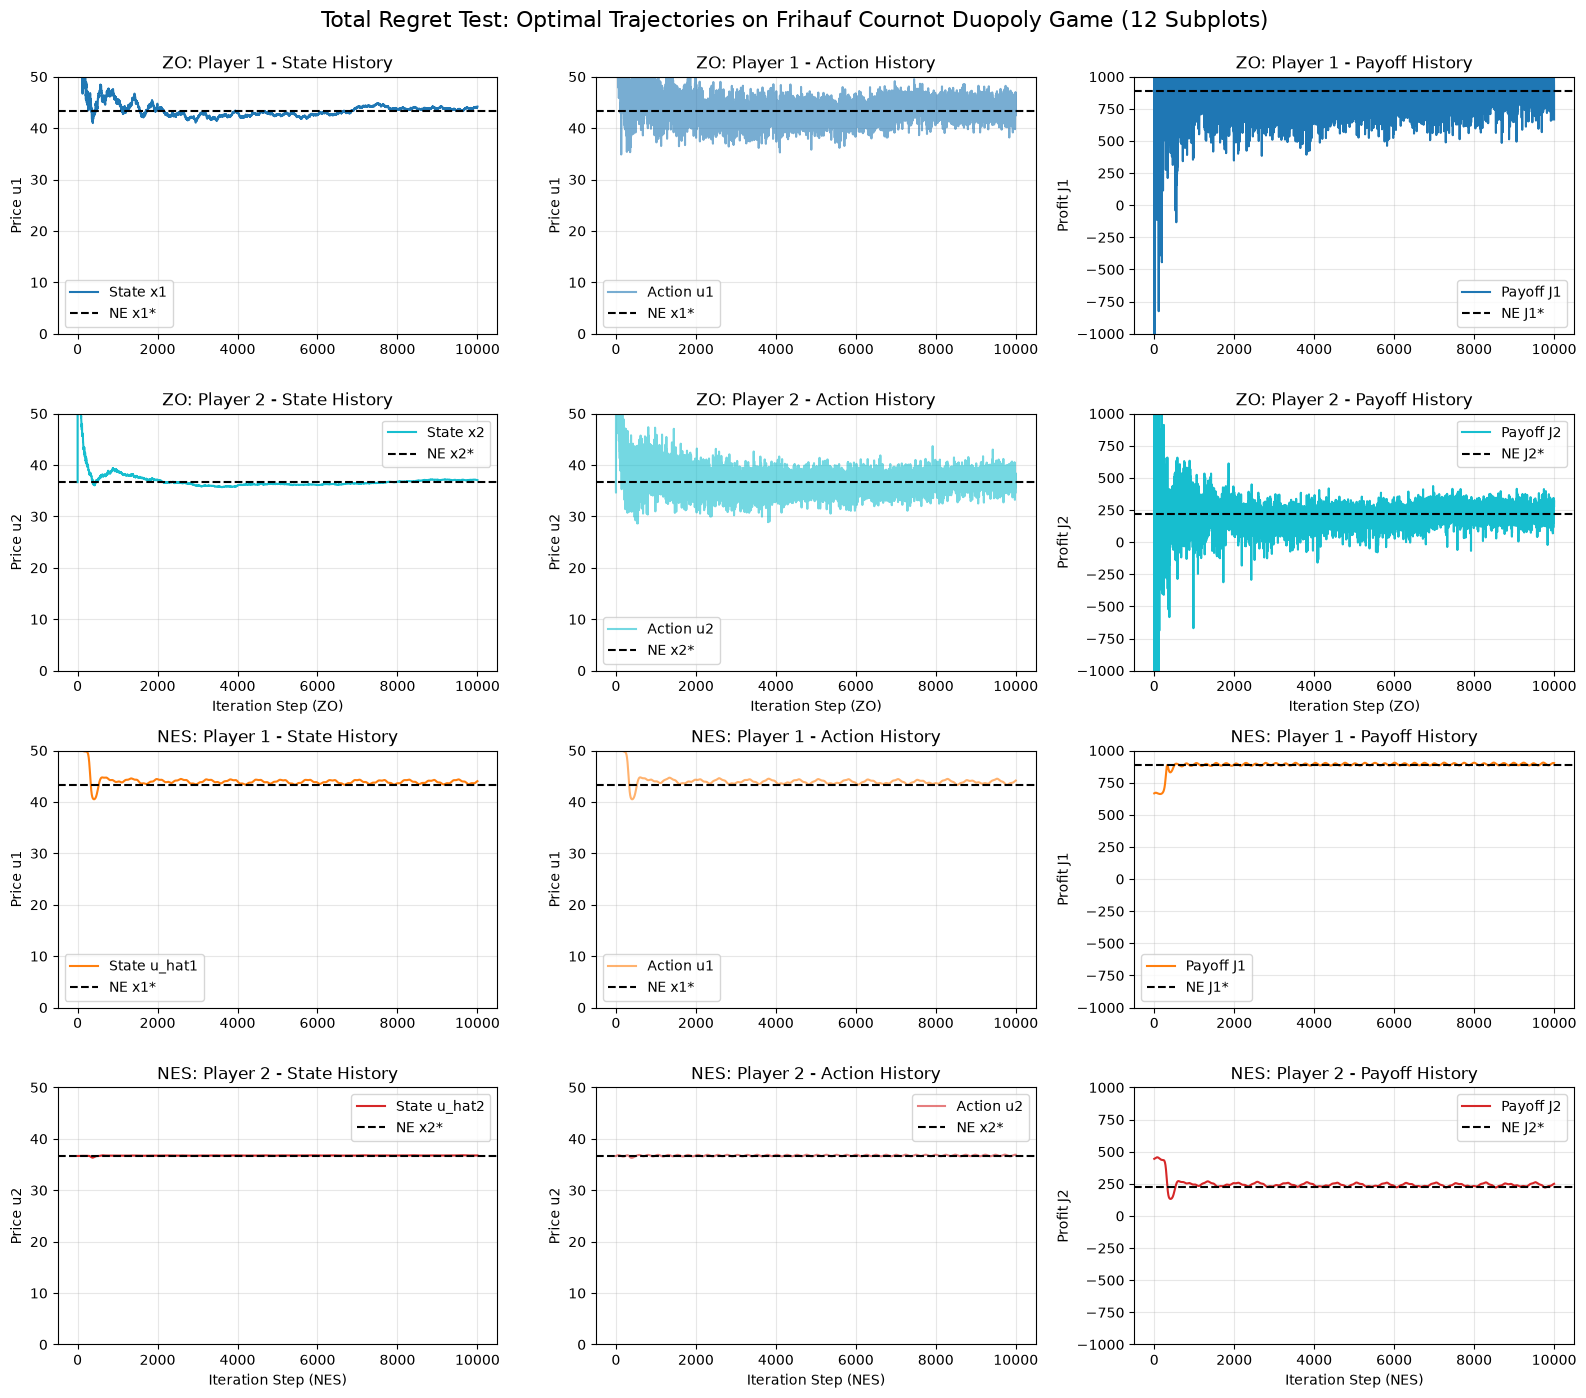

Regret dynamics plot saved to: data/01_total_regret_test/cumulative_regret.png


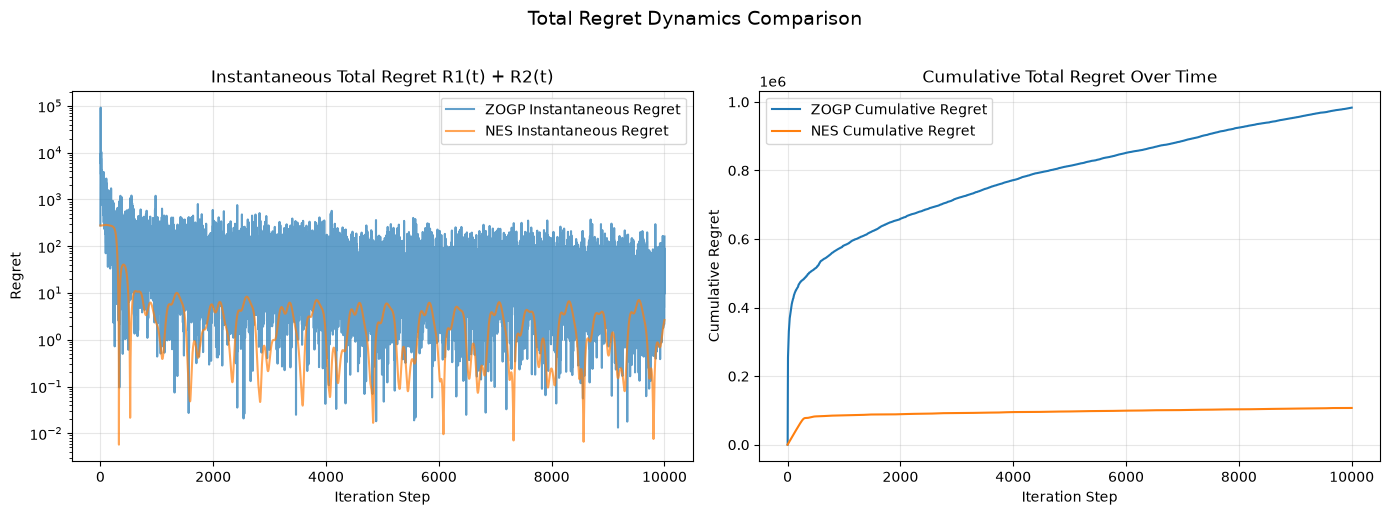

TOTAL REGRET TEST SUMMARY
Nash Equilibrium Reference: u* = [43.3333, 36.6667]
Optimal Payoffs Reference:  J* = [888.8889, 222.2222]
----------------------------------------------------------------------
ZOGrandientPlay:
  Best Parameters:     {'epsilon': 1e-06, 'v': 9.857193797826767, 'a': 14.762035921216011, 'game_id': 'game_0', 'is_default': False, 'objective_value': 6.048575191151755}
  Optimization Loss:   6.0486 (log10 Total Regret)
  Simulation Time:     0.39 seconds (10001 steps)
  Final State:         u_hat = [44.1871, 37.0616]
  Final Error:         ||u_hat - u*|| = 0.9407
  Sim Total Regret:    983387.9392 (Mean per step: 98.3290)
----------------------------------------------------------------------
NESeeking:
  Best Parameters:     {'dt': 0.001, 'omega_h[0]': 10.0, 'omega_h[1]': 10.0, 'k[0,0]': 5.683158129453659, 'k[1,0]': 0.3070331424474716, 'a[0,0]': 0.14412960946559908, 'a[1,0]': 0.14295399606227877, 'omega[0,0]': 15.289424937218428, 'omega[1,0]': 25.331521034240723, 'ga

In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

from payoffnash import (
    EstimateHistory,
    MetaParamOptimization,
    NESeeking,
    QuadraticGame,
    ZOGrandientPlay,
)

# 1. Output directory for total regret test artifacts
regret_dir = "data/01_total_regret_test"
os.makedirs(regret_dir, exist_ok=True)

# 2. Define the exact Cournot duopoly game from Frihauf et al. (2012)
N = 2
action_sets = [[(0.0, 300.0)], [(0.0, 300.0)]]
Sd, p, m1, m2 = 100.0, 0.2, 30.0, 30.0

def J1(u1, u2):
    s1 = Sd - (u1 - u2) / p
    return float(s1 * (u1 - m1))

def J2(u1, u2):
    s2 = (u1 - u2) / p
    return float(s2 * (u2 - m2))

H = np.array([[-10.0, 5.0], [5.0, -10.0]], dtype=float)
d = np.array([250.0, 150.0], dtype=float)
c = np.array([-3000.0, 0.0], dtype=float)
u_star = np.array([130.0 / 3.0, 110.0 / 3.0], dtype=float)
opt_payoffs = [8000.0 / 9.0, 2000.0 / 9.0]

cournot_game = QuadraticGame(
    N=N,
    action_sets=action_sets,
    payoff_functions=[J1, J2],
    H=H,
    d=d,
    c=c,
    nash_equilibrium=u_star,
    optimal_payoffs=opt_payoffs,
)

initial_actions = np.array([[50.0], [36.6667]], dtype=float)

# 3. Cost function: Log10 Total Regret across both players over all steps
def total_regret_cost(game: QuadraticGame, history: EstimateHistory) -> float:
    """
    Computes log10 of total systemic regret across both players over all steps.
    Using log10 stabilizes the Gaussian Process in MTBO, preventing scale distortion
    from initial transients spanning multiple orders of magnitude (10^4 to 10^9).
    """
    u1 = history.action_history[:, 0]
    u2 = history.action_history[:, 1]
    br1 = 25.0 + 0.5 * u2
    br2 = 15.0 + 0.5 * u1
    regret1 = 5.0 * (u1 - br1) ** 2
    regret2 = 5.0 * (u2 - br2) ** 2
    tot = float(np.sum(regret1 + regret2))
    return float(np.log10(max(tot, 1e-12)))

# 4. ZOGrandientPlay MTBO (Minimizing Log10 Total Regret)
zo_search_space = {
    "v": (0.5, 10.0),
    "a": (1.0, 150.0),
}
zo_fixed_params = {
    "epsilon": 1e-6,
}

print("--- Starting ZOGrandientPlay MTBO (Log10 Total Regret, 40 evaluations, 10,000 steps each) ---")
zo_opt = MetaParamOptimization(
    game_ensemble=[cournot_game],
    search_space=zo_search_space,
    algorithm_class=ZOGrandientPlay,
    cost_function=total_regret_cost,
    output_path=os.path.join(regret_dir, "zo_cournot_regret_results.csv"),
    num_steps=10000,
    n_init=10,
    max_bo_steps=30,
    eps_ei=1e-4,
    seed=42,
    fixed_params=zo_fixed_params,
    initial_actions=initial_actions,
)
zo_results = zo_opt.run_optimization_loop()
zo_best_theta = zo_opt.best_thetas[0]
print(f"ZOGrandientPlay Best Parameters: {zo_results[0]}\n")

# 5. NESeeking MTBO (Minimizing Log10 Total Regret)
ne_search_space = {
    "k[0,0]": (0.1, 10.0),
    "k[1,0]": (0.1, 10.0),
    "a[0,0]": (0.01, 0.2),
    "a[1,0]": (0.01, 0.2),
    "omega[0,0]": (15.0, 35.0),
    "omega[1,0]": (15.0, 35.0),
}
ne_fixed_params = {
    "dt": 0.001,
    "omega_h": np.array([10.0, 10.0]),
}

print("--- Starting NESeeking MTBO (Log10 Total Regret, 40 evaluations, 10,000 steps each) ---")
ne_opt = MetaParamOptimization(
    game_ensemble=[cournot_game],
    search_space=ne_search_space,
    algorithm_class=NESeeking,
    cost_function=total_regret_cost,
    output_path=os.path.join(regret_dir, "ne_cournot_regret_results.csv"),
    num_steps=10000,
    n_init=10,
    max_bo_steps=30,
    eps_ei=1e-4,
    seed=42,
    fixed_params=ne_fixed_params,
    initial_actions=initial_actions,
)
ne_results = ne_opt.run_optimization_loop()
ne_best_theta = ne_opt.best_thetas[0]
print(f"NESeeking Best Parameters: {ne_results[0]}\n")

# 6. Simulate optimal trajectories (num_steps = 10000)
print("--- Simulating optimal trajectories (num_steps = 10000) ---")
zo_best_estimator = zo_opt.build_estimator(zo_best_theta, cournot_game)
ne_best_estimator = ne_opt.build_estimator(ne_best_theta, cournot_game)

t0_zo = time.time()
zo_history = zo_best_estimator.estimate(initial_actions, num_steps=10000)
zo_sim_time = time.time() - t0_zo

t0_ne = time.time()
ne_history = ne_best_estimator.estimate(initial_actions, num_steps=10000)
ne_sim_time = time.time() - t0_ne

# Compute instantaneous and cumulative regret profiles for visualization
zo_u1 = zo_history.action_history[:, 0]
zo_u2 = zo_history.action_history[:, 1]
zo_r1 = 5.0 * (zo_u1 - (25.0 + 0.5 * zo_u2)) ** 2
zo_r2 = 5.0 * (zo_u2 - (15.0 + 0.5 * zo_u1)) ** 2
zo_tot_regret = zo_r1 + zo_r2
zo_cum_regret = np.cumsum(zo_tot_regret)

ne_u1 = ne_history.action_history[:, 0]
ne_u2 = ne_history.action_history[:, 1]
ne_r1 = 5.0 * (ne_u1 - (25.0 + 0.5 * ne_u2)) ** 2
ne_r2 = 5.0 * (ne_u2 - (15.0 + 0.5 * ne_u1)) ** 2
ne_tot_regret = ne_r1 + ne_r2
ne_cum_regret = np.cumsum(ne_tot_regret)

# 7. Plot 12 Subplots: State, Action, Payoff for both players and both algorithms
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
steps_zo = np.arange(len(zo_history.state_history))
steps_ne = np.arange(len(ne_history.state_history))

# Share x-axis within ZO (rows 0, 1) and within NES (rows 2, 3)
for col in range(3):
    axes[0, col].sharex(axes[1, col])
    axes[2, col].sharex(axes[3, col])

# Row 0: ZO - Player 1
axes[0, 0].plot(steps_zo, zo_history.state_history[:, 0], color="tab:blue", label="State x1")
axes[0, 0].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[0, 0].set_title("ZO: Player 1 - State History")
axes[0, 0].set_ylabel("Price u1")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(steps_zo, zo_history.action_history[:, 0], color="tab:blue", alpha=0.6, label="Action u1")
axes[0, 1].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[0, 1].set_title("ZO: Player 1 - Action History")
axes[0, 1].set_ylabel("Price u1")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].plot(steps_zo, zo_history.payoff_history[:, 0], color="tab:blue", label="Payoff J1")
axes[0, 2].axhline(opt_payoffs[0], color="black", linestyle="--", label="NE J1*")
axes[0, 2].set_title("ZO: Player 1 - Payoff History")
axes[0, 2].set_ylabel("Profit J1")
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# Row 1: ZO - Player 2
axes[1, 0].plot(steps_zo, zo_history.state_history[:, 1], color="tab:cyan", label="State x2")
axes[1, 0].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[1, 0].set_title("ZO: Player 2 - State History")
axes[1, 0].set_xlabel("Iteration Step (ZO)")
axes[1, 0].set_ylabel("Price u2")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(steps_zo, zo_history.action_history[:, 1], color="tab:cyan", alpha=0.6, label="Action u2")
axes[1, 1].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[1, 1].set_title("ZO: Player 2 - Action History")
axes[1, 1].set_xlabel("Iteration Step (ZO)")
axes[1, 1].set_ylabel("Price u2")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(steps_zo, zo_history.payoff_history[:, 1], color="tab:cyan", label="Payoff J2")
axes[1, 2].axhline(opt_payoffs[1], color="black", linestyle="--", label="NE J2*")
axes[1, 2].set_title("ZO: Player 2 - Payoff History")
axes[1, 2].set_xlabel("Iteration Step (ZO)")
axes[1, 2].set_ylabel("Profit J2")
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

# Row 2: NES - Player 1
axes[2, 0].plot(steps_ne, ne_history.state_history[:, 0], color="tab:orange", label="State u_hat1")
axes[2, 0].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[2, 0].set_title("NES: Player 1 - State History")
axes[2, 0].set_ylabel("Price u1")
axes[2, 0].legend()
axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(steps_ne, ne_history.action_history[:, 0], color="tab:orange", alpha=0.6, label="Action u1")
axes[2, 1].axhline(u_star[0], color="black", linestyle="--", label="NE x1*")
axes[2, 1].set_title("NES: Player 1 - Action History")
axes[2, 1].set_ylabel("Price u1")
axes[2, 1].legend()
axes[2, 1].grid(True, alpha=0.3)

axes[2, 2].plot(steps_ne, ne_history.payoff_history[:, 0], color="tab:orange", label="Payoff J1")
axes[2, 2].axhline(opt_payoffs[0], color="black", linestyle="--", label="NE J1*")
axes[2, 2].set_title("NES: Player 1 - Payoff History")
axes[2, 2].set_ylabel("Profit J1")
axes[2, 2].legend()
axes[2, 2].grid(True, alpha=0.3)

# Row 3: NES - Player 2
axes[3, 0].plot(steps_ne, ne_history.state_history[:, 1], color="tab:red", label="State u_hat2")
axes[3, 0].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[3, 0].set_title("NES: Player 2 - State History")
axes[3, 0].set_xlabel("Iteration Step (NES)")
axes[3, 0].set_ylabel("Price u2")
axes[3, 0].legend()
axes[3, 0].grid(True, alpha=0.3)

axes[3, 1].plot(steps_ne, ne_history.action_history[:, 1], color="tab:red", alpha=0.6, label="Action u2")
axes[3, 1].axhline(u_star[1], color="black", linestyle="--", label="NE x2*")
axes[3, 1].set_title("NES: Player 2 - Action History")
axes[3, 1].set_xlabel("Iteration Step (NES)")
axes[3, 1].set_ylabel("Price u2")
axes[3, 1].legend()
axes[3, 1].grid(True, alpha=0.3)

axes[3, 2].plot(steps_ne, ne_history.payoff_history[:, 1], color="tab:red", label="Payoff J2")
axes[3, 2].axhline(opt_payoffs[1], color="black", linestyle="--", label="NE J2*")
axes[3, 2].set_title("NES: Player 2 - Payoff History")
axes[3, 2].set_xlabel("Iteration Step (NES)")
axes[3, 2].set_ylabel("Profit J2")
axes[3, 2].legend()
axes[3, 2].grid(True, alpha=0.3)

# Apply y-axis limits: [0, 50] for states and actions, [-1000, 1000] for payoffs
for r in range(4):
    axes[r, 0].set_ylim(0, 50)
    axes[r, 1].set_ylim(0, 50)
    axes[r, 2].set_ylim(-1000, 1000)

plt.suptitle("Total Regret Test: Optimal Trajectories on Frihauf Cournot Duopoly Game (12 Subplots)", fontsize=16, y=0.995)
plt.tight_layout()
traj_plot_path = os.path.join(regret_dir, "total_regret_trajectories.png")
plt.savefig(traj_plot_path, dpi=300, bbox_inches="tight")
print(f"Trajectory plot saved to: {traj_plot_path}")
plt.show()

# 8. Plot Regret Trajectories: Instantaneous & Cumulative Regret
fig, (ax_inst, ax_cum) = plt.subplots(1, 2, figsize=(14, 5))

ax_inst.plot(steps_zo, zo_tot_regret, color="tab:blue", alpha=0.7, label="ZOGP Instantaneous Regret")
ax_inst.plot(steps_ne, ne_tot_regret, color="tab:orange", alpha=0.7, label="NES Instantaneous Regret")
ax_inst.set_title("Instantaneous Total Regret R1(t) + R2(t)")
ax_inst.set_xlabel("Iteration Step")
ax_inst.set_ylabel("Regret")
ax_inst.set_yscale("log")
ax_inst.grid(True, alpha=0.3)
ax_inst.legend()

ax_cum.plot(steps_zo, zo_cum_regret, color="tab:blue", lw=1.5, label="ZOGP Cumulative Regret")
ax_cum.plot(steps_ne, ne_cum_regret, color="tab:orange", lw=1.5, label="NES Cumulative Regret")
ax_cum.set_title("Cumulative Total Regret Over Time")
ax_cum.set_xlabel("Iteration Step")
ax_cum.set_ylabel("Cumulative Regret")
ax_cum.grid(True, alpha=0.3)
ax_cum.legend()

plt.suptitle("Total Regret Dynamics Comparison", fontsize=14, y=1.02)
plt.tight_layout()
regret_plot_path = os.path.join(regret_dir, "cumulative_regret.png")
plt.savefig(regret_plot_path, dpi=300, bbox_inches="tight")
print(f"Regret dynamics plot saved to: {regret_plot_path}")
plt.show()

# 9. Print comprehensive summary
print("=" * 70)
print("TOTAL REGRET TEST SUMMARY")
print("=" * 70)
print(f"Nash Equilibrium Reference: u* = [{u_star[0]:.4f}, {u_star[1]:.4f}]")
print(f"Optimal Payoffs Reference:  J* = [{opt_payoffs[0]:.4f}, {opt_payoffs[1]:.4f}]")
print("-" * 70)
print("ZOGrandientPlay:")
print(f"  Best Parameters:     {zo_results[0]}")
print(f"  Optimization Loss:   {zo_results[0]['objective_value']:.4f} (log10 Total Regret)")
print(f"  Simulation Time:     {zo_sim_time:.2f} seconds ({len(zo_history.state_history)} steps)")
print(f"  Final State:         u_hat = [{zo_history.state_history[-1][0]:.4f}, {zo_history.state_history[-1][1]:.4f}]")
print(f"  Final Error:         ||u_hat - u*|| = {np.linalg.norm(zo_history.state_history[-1] - u_star):.4f}")
print(f"  Sim Total Regret:    {zo_cum_regret[-1]:.4f} (Mean per step: {np.mean(zo_tot_regret):.4f})")
print("-" * 70)
print("NESeeking:")
print(f"  Best Parameters:     {ne_results[0]}")
print(f"  Optimization Loss:   {ne_results[0]['objective_value']:.4f} (log10 Total Regret)")
print(f"  Simulation Time:     {ne_sim_time:.2f} seconds ({len(ne_history.state_history)} steps)")
print(f"  Final State:         u_hat = [{ne_history.state_history[-1][0]:.4f}, {ne_history.state_history[-1][1]:.4f}]")
print(f"  Final Error:         ||u_hat - u*|| = {np.linalg.norm(ne_history.state_history[-1] - u_star):.4f}")
print(f"  Sim Total Regret:    {ne_cum_regret[-1]:.4f} (Mean per step: {np.mean(ne_tot_regret):.4f})")
print("=" * 70)


## 0.2 Benchmark: 6-Dimensional Hyperparameter Tuning (NESeeking) vs. Optuna Baseline

This benchmark tunes **all 6 continuous hyperparameters** of `NESeeking` on the 2-player Cournot duopoly price game (Frihauf et al. 2012) using **Total Regret** minimization over 10,000 steps ($dt = 0.001$, $\omega_h = 10.0$ fixed) across **512 evaluations**:

### Search Space (6 Continuous Dimensions):
- **Integration Gains:** $k[0,0], k[1,0] \in [0.1, 10.0]$
- **Perturbation Amplitudes:** $a[0,0], a[1,0] \in [0.01, 0.2]$
- **Dither Frequencies:** $\omega[0,0], \omega[1,0] \in [15.0, 35.0]$
- *(Fixed: $dt = 0.001$, $\omega_h = [10.0, 10.0]^T$; $\phi$ eliminated per Frihauf et al. 2012)*

### Optimization Setup (512 Total Evaluations):
1. **Refactored MTBO:** Uses dimension-scaled dynamic Sobol candidate sampling ($N_{\text{cands}} = \min(256 \cdot 6, 4096) = 1536$ candidates per BO step), Swersky Eq. 8 full covariance sum across tasks, batched memory-safe tensor operations, direct task indexing, and safety masking against redundant queries across 64 initial Latin Hypercube samples and 448 BO steps ($n_{\text{init}}=64, n_{\text{bo}}=448$, seed 42).
2. **Baseline Model (Optuna):** Runs an identical 512-evaluation budget (64 startup trials, 448 TPE steps, seed 42) using Optuna's Tree-structured Parzen Estimator (`TPESampler`) on the exact same 10,000-step simulation loss.
3. **Artifacts:** Output CSVs, trajectory plots, and cumulative regret dynamics saved to `data/02_regret_benchmark/`.


In [3]:
import os
import time
import csv
import numpy as np
import matplotlib.pyplot as plt
import torch
import optuna

from payoffnash.game_ensemble import QuadraticGame
from payoffnash.ne_seeking import NESeeking
from payoffnash.mtbo import MetaParamOptimization
from payoffnash.common import EstimateHistory

bench_dir = "data/02_regret_benchmark"
os.makedirs(bench_dir, exist_ok=True)

N = 2
action_sets = [[(0.0, 300.0)], [(0.0, 300.0)]]
Sd, p, m1, m2 = 100.0, 0.2, 30.0, 30.0

def J1(u1, u2):
    s1 = Sd - (u1 - u2) / p
    return float(s1 * (u1 - m1))

def J2(u1, u2):
    s2 = (u1 - u2) / p
    return float(s2 * (u2 - m2))

H = np.array([[-10.0, 5.0], [5.0, -10.0]], dtype=float)
d = np.array([250.0, 150.0], dtype=float)
c = np.array([-3000.0, 0.0], dtype=float)
u_star = np.array([130.0 / 3.0, 110.0 / 3.0], dtype=float)
opt_payoffs = [8000.0 / 9.0, 2000.0 / 9.0]

game = QuadraticGame(
    N=N,
    action_sets=action_sets,
    payoff_functions=[J1, J2],
    H=H,
    d=d,
    c=c,
    nash_equilibrium=u_star,
    optimal_payoffs=opt_payoffs,
)

initial_actions = np.array([[50.0], [36.6667]], dtype=float)

def total_regret_cost(game: QuadraticGame, history: EstimateHistory) -> float:
    u1 = history.action_history[:, 0]
    u2 = history.action_history[:, 1]
    br1 = 25.0 + 0.5 * u2
    br2 = 15.0 + 0.5 * u1
    reg1 = 5.0 * (u1 - br1) ** 2
    reg2 = 5.0 * (u2 - br2) ** 2
    tot = float(np.sum(reg1 + reg2))
    return float(np.log10(max(tot, 1e-12)))

ne_search_space = {
    "k[0,0]": (0.1, 10.0),
    "k[1,0]": (0.1, 10.0),
    "a[0,0]": (0.01, 0.2),
    "a[1,0]": (0.01, 0.2),
    "omega[0,0]": (15.0, 35.0),
    "omega[1,0]": (15.0, 35.0),
}
fixed_params = {
    "dt": 0.001,
    "omega_h": np.array([10.0, 10.0]),
}

TOTAL_EVALS = 512
N_INIT = 64
N_BO = TOTAL_EVALS - N_INIT  # 448

print(f"=== 1. Running Refactored MTBO (6D, {TOTAL_EVALS} total evals: {N_INIT} init + {N_BO} BO, 10,000 steps) ===", flush=True)
t0_mtbo = time.time()
mtbo_opt = MetaParamOptimization(
    game_ensemble=[game],
    search_space=ne_search_space,
    algorithm_class=NESeeking,
    cost_function=total_regret_cost,
    output_path=os.path.join(bench_dir, "mtbo_regret_results.csv"),
    num_steps=10000,
    n_init=N_INIT,
    max_bo_steps=N_BO,
    eps_ei=None,
    seed=42,
    fixed_params=fixed_params,
    initial_actions=initial_actions,
)
mtbo_results = mtbo_opt.run_optimization_loop()
t_mtbo = time.time() - t0_mtbo
print(f"MTBO completed in {t_mtbo:.2f}s ({t_mtbo/60:.2f} min)!", flush=True)

mtbo_best = mtbo_results[0]
print(f"MTBO Best log10(Regret): {mtbo_best['objective_value']:.4f} (Regret: {10**mtbo_best['objective_value']:.2f})", flush=True)

print(f"\n=== 2. Running Optuna TPE Baseline (6D, {TOTAL_EVALS} trials: {N_INIT} startup + {N_BO} TPE, 10,000 steps) ===", flush=True)
t0_optuna = time.time()

def optuna_objective(trial: optuna.Trial) -> float:
    k0 = trial.suggest_float("k[0,0]", 0.1, 10.0)
    k1 = trial.suggest_float("k[1,0]", 0.1, 10.0)
    a0 = trial.suggest_float("a[0,0]", 0.01, 0.2)
    a1 = trial.suggest_float("a[1,0]", 0.01, 0.2)
    w0 = trial.suggest_float("omega[0,0]", 15.0, 35.0)
    w1 = trial.suggest_float("omega[1,0]", 15.0, 35.0)

    estimator = NESeeking(
        game,
        k=np.array([[k0], [k1]]),
        a=np.array([[a0], [a1]]),
        omega=np.array([[w0], [w1]]),
        omega_h=np.array([10.0, 10.0]),
        dt=0.001,
    )
    res = estimator.estimate(initial_actions, num_steps=10000)
    return total_regret_cost(game, res)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sampler = optuna.samplers.TPESampler(n_startup_trials=N_INIT, seed=42)
study = optuna.create_study(direction="minimize", sampler=sampler)

step_count = 0
def optuna_callback(study, trial):
    global step_count
    step_count += 1
    if step_count % 50 == 0 or step_count == TOTAL_EVALS:
        print(f"  [Optuna Trial {step_count}/{TOTAL_EVALS}] loss={trial.value:.5f}, best so far={study.best_value:.5f}", flush=True)

study.optimize(optuna_objective, n_trials=TOTAL_EVALS, callbacks=[optuna_callback])
t_optuna = time.time() - t0_optuna
print(f"Optuna completed in {t_optuna:.2f}s ({t_optuna/60:.2f} min)!", flush=True)

optuna_best = study.best_params
optuna_best_val = study.best_value
print(f"Optuna Best log10(Regret): {optuna_best_val:.4f} (Regret: {10**optuna_best_val:.2f})", flush=True)

# Export Optuna trials
optuna_csv_path = os.path.join(bench_dir, "optuna_regret_results.csv")
with open(optuna_csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    keys = list(ne_search_space.keys())
    writer.writerow(["trial_id"] + keys + ["objective_value"])
    for trial in study.trials:
        row = [trial.number] + [trial.params[k] for k in keys] + [trial.value]
        writer.writerow(row)

# 5. Full Trajectory Simulation for Head-to-Head Comparison
print("\n=== 3. Simulating Full Trajectories for Head-to-Head Comparison ===", flush=True)
ne_mtbo = NESeeking(
    game,
    k=np.array([[mtbo_best["k[0,0]"]], [mtbo_best["k[1,0]"]]]),
    a=np.array([[mtbo_best["a[0,0]"]], [mtbo_best["a[1,0]"]]]),
    omega=np.array([[mtbo_best["omega[0,0]"]], [mtbo_best["omega[1,0]"]]]),
    omega_h=np.array([10.0, 10.0]),
    dt=0.001,
)
res_mtbo = ne_mtbo.estimate(initial_actions, num_steps=10000)

ne_optuna = NESeeking(
    game,
    k=np.array([[optuna_best["k[0,0]"]], [optuna_best["k[1,0]"]]]),
    a=np.array([[optuna_best["a[0,0]"]], [optuna_best["a[1,0]"]]]),
    omega=np.array([[optuna_best["omega[0,0]"]], [optuna_best["omega[1,0]"]]]),
    omega_h=np.array([10.0, 10.0]),
    dt=0.001,
)
res_optuna = ne_optuna.estimate(initial_actions, num_steps=10000)

def compute_regrets(res):
    u1, u2 = res.action_history[:, 0], res.action_history[:, 1]
    br1, br2 = 25.0 + 0.5 * u2, 15.0 + 0.5 * u1
    r1, r2 = 5.0 * (u1 - br1) ** 2, 5.0 * (u2 - br2) ** 2
    inst = r1 + r2
    cum = np.cumsum(inst)
    return inst, cum

inst_mtbo, cum_mtbo = compute_regrets(res_mtbo)
inst_optuna, cum_optuna = compute_regrets(res_optuna)

dist_mtbo = float(np.mean(np.linalg.norm(res_mtbo.state_history - u_star, axis=-1)))
dist_optuna = float(np.mean(np.linalg.norm(res_optuna.state_history - u_star, axis=-1)))
final_dist_mtbo = float(np.linalg.norm(res_mtbo.state_history[-1] - u_star))
final_dist_optuna = float(np.linalg.norm(res_optuna.state_history[-1] - u_star))

print("\n--- Final Benchmark Summary (512 Evaluations) ---", flush=True)
print(f"MTBO:   Total Regret = {cum_mtbo[-1]:.2f} (log10={np.log10(cum_mtbo[-1]):.4f}), Mean State Dist = {dist_mtbo:.4f}, Final Dist = {final_dist_mtbo:.4f}", flush=True)
print(f"Optuna: Total Regret = {cum_optuna[-1]:.2f} (log10={np.log10(cum_optuna[-1]):.4f}), Mean State Dist = {dist_optuna:.4f}, Final Dist = {final_dist_optuna:.4f}", flush=True)

# Save comparison summary CSV
summary_csv = os.path.join(bench_dir, "benchmark_comparison_summary.csv")
with open(summary_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Optimizer", "Total Regret", "log10(Regret)", "Mean State Dist", "Final State Dist", "Wall Time (s)"])
    writer.writerow(["Refactored MTBO", cum_mtbo[-1], np.log10(cum_mtbo[-1]), dist_mtbo, final_dist_mtbo, t_mtbo])
    writer.writerow(["Optuna (TPE)", cum_optuna[-1], np.log10(cum_optuna[-1]), dist_optuna, final_dist_optuna, t_optuna])

# 6. Plots
steps = np.arange(len(cum_mtbo))
t_axis = steps * 0.001

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(t_axis, inst_mtbo, label=f"MTBO (Final={cum_mtbo[-1]:.0f})", color="tab:blue", alpha=0.8)
plt.plot(t_axis, inst_optuna, label=f"Optuna TPE (Final={cum_optuna[-1]:.0f})", color="tab:orange", alpha=0.8)
plt.yscale("log")
plt.xlabel("Time (s)")
plt.ylabel("Instantaneous Regret $R_1(t) + R_2(t)$")
plt.title("Instantaneous Regret Dynamics (512 Evals)")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(t_axis, cum_mtbo, label=f"MTBO (Sum={cum_mtbo[-1]:.0f})", color="tab:blue", lw=2)
plt.plot(t_axis, cum_optuna, label=f"Optuna TPE (Sum={cum_optuna[-1]:.0f})", color="tab:orange", lw=2)
plt.yscale("log")
plt.xlabel("Time (s)")
plt.ylabel("Cumulative Regret")
plt.title("Cumulative Regret Comparison (512 Evals)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(bench_dir, "cumulative_regret_comparison.png"), dpi=300)
plt.close()

# 12 Subplot comparison figure
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes[0, 0].plot(t_axis, res_mtbo.state_history[:, 0], label=r"State $\hat{u}_1$", color="navy")
axes[0, 0].axhline(u_star[0], color="red", linestyle="--", label=r"NE $u_1^*$")
axes[0, 0].set_ylim([0, 50])
axes[0, 0].set_title("MTBO Player 1 State")
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot(t_axis, res_mtbo.state_history[:, 1], label=r"State $\hat{u}_2$", color="darkgreen")
axes[0, 1].axhline(u_star[1], color="red", linestyle="--", label=r"NE $u_2^*$")
axes[0, 1].set_ylim([0, 50])
axes[0, 1].set_title("MTBO Player 2 State")
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[0, 2].plot(t_axis, res_mtbo.action_history[:, 0], label=r"Action $u_1$", color="blue", alpha=0.5)
axes[0, 2].plot(t_axis, res_mtbo.action_history[:, 1], label=r"Action $u_2$", color="green", alpha=0.5)
axes[0, 2].axhline(u_star[0], color="red", linestyle="--")
axes[0, 2].axhline(u_star[1], color="red", linestyle="--")
axes[0, 2].set_ylim([0, 50])
axes[0, 2].set_title("MTBO Actions $(u_1, u_2)$")
axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].legend()

axes[1, 0].plot(t_axis, res_mtbo.payoff_history[:, 0], label=r"Payoff $J_1$", color="navy")
axes[1, 0].axhline(opt_payoffs[0], color="red", linestyle="--", label="NE Payoff")
axes[1, 0].set_ylim([-1000, 1000])
axes[1, 0].set_title("MTBO Player 1 Payoff")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(t_axis, res_mtbo.payoff_history[:, 1], label=r"Payoff $J_2$", color="darkgreen")
axes[1, 1].axhline(opt_payoffs[1], color="red", linestyle="--", label="NE Payoff")
axes[1, 1].set_ylim([-1000, 1000])
axes[1, 1].set_title("MTBO Player 2 Payoff")
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

axes[1, 2].plot(t_axis, inst_mtbo, label="Instant Regret", color="purple")
axes[1, 2].set_yscale("log")
axes[1, 2].set_title("MTBO Regret Dynamics")
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend()

axes[2, 0].plot(t_axis, res_optuna.state_history[:, 0], label=r"State $\hat{u}_1$", color="navy")
axes[2, 0].axhline(u_star[0], color="red", linestyle="--", label=r"NE $u_1^*$")
axes[2, 0].set_ylim([0, 50])
axes[2, 0].set_title("Optuna TPE Player 1 State")
axes[2, 0].grid(True, alpha=0.3)
axes[2, 0].legend()

axes[2, 1].plot(t_axis, res_optuna.state_history[:, 1], label=r"State $\hat{u}_2$", color="darkgreen")
axes[2, 1].axhline(u_star[1], color="red", linestyle="--", label=r"NE $u_2^*$")
axes[2, 1].set_ylim([0, 50])
axes[2, 1].set_title("Optuna TPE Player 2 State")
axes[2, 1].grid(True, alpha=0.3)
axes[2, 1].legend()

axes[2, 2].plot(t_axis, res_optuna.action_history[:, 0], label=r"Action $u_1$", color="blue", alpha=0.5)
axes[2, 2].plot(t_axis, res_optuna.action_history[:, 1], label=r"Action $u_2$", color="green", alpha=0.5)
axes[2, 2].axhline(u_star[0], color="red", linestyle="--")
axes[2, 2].axhline(u_star[1], color="red", linestyle="--")
axes[2, 2].set_ylim([0, 50])
axes[2, 2].set_title("Optuna TPE Actions $(u_1, u_2)$")
axes[2, 2].grid(True, alpha=0.3)
axes[2, 2].legend()

axes[3, 0].plot(t_axis, res_optuna.payoff_history[:, 0], label=r"Payoff $J_1$", color="navy")
axes[3, 0].axhline(opt_payoffs[0], color="red", linestyle="--", label="NE Payoff")
axes[3, 0].set_ylim([-1000, 1000])
axes[3, 0].set_title("Optuna TPE Player 1 Payoff")
axes[3, 0].grid(True, alpha=0.3)
axes[3, 0].legend()

axes[3, 1].plot(t_axis, res_optuna.payoff_history[:, 1], label=r"Payoff $J_2$", color="darkgreen")
axes[3, 1].axhline(opt_payoffs[1], color="red", linestyle="--", label="NE Payoff")
axes[3, 1].set_ylim([-1000, 1000])
axes[3, 1].set_title("Optuna TPE Player 2 Payoff")
axes[3, 1].grid(True, alpha=0.3)
axes[3, 1].legend()

axes[3, 2].plot(t_axis, inst_optuna, label="Instant Regret", color="purple")
axes[3, 2].set_yscale("log")
axes[3, 2].set_title("Optuna TPE Regret Dynamics")
axes[3, 2].grid(True, alpha=0.3)
axes[3, 2].legend()

plt.tight_layout()
plt.savefig(os.path.join(bench_dir, "trajectory_comparison_12subplots.png"), dpi=300)
plt.close()

print(f"\nAll benchmark artifacts saved to {bench_dir}/ successfully!", flush=True)


=== 1. Running Refactored MTBO (6D, 512 total evals: 64 init + 448 BO, 10,000 steps) ===


/home/bruno/Documents/PayoffBasedNEComparison/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  [BO Step 1/448] Task 0: loss=5.57221, best_loss=5.15839
  [BO Step 25/448] Task 0: loss=9.55361, best_loss=4.92279
  [BO Step 50/448] Task 0: loss=4.86850, best_loss=4.86850
  [BO Step 75/448] Task 0: loss=6.64545, best_loss=4.80527
  [BO Step 100/448] Task 0: loss=4.80450, best_loss=4.78918
  [BO Step 125/448] Task 0: loss=8.03352, best_loss=4.71104
  [BO Step 150/448] Task 0: loss=4.82017, best_loss=4.71104
  [BO Step 175/448] Task 0: loss=9.20586, best_loss=4.71104
  [BO Step 200/448] Task 0: loss=6.24821, best_loss=4.71104
  [BO Step 225/448] Task 0: loss=5.21204, best_loss=4.71071
  [BO Step 250/448] Task 0: loss=5.08552, best_loss=4.71071
  [BO Step 275/448] Task 0: loss=4.98553, best_loss=4.70234
  [BO Step 300/448] Task 0: loss=4.82131, best_loss=4.70234
  [BO Step 325/448] Task 0: loss=5.20241, best_loss=4.70234
  [BO Step 350/448] Task 0: loss=4.94959, best_loss=4.69520
  [BO Step 375/448] Task 0: loss=4.96426, best_loss=4.68375
  [BO Step 400/448] Task 0: loss=4.77727, bes

In [4]:
import os
import time
import csv
import numpy as np
import matplotlib.pyplot as plt
import optuna

from payoffnash import (
    Game,
    QuadraticGame,
    generate_quadratic_games,
    MetaParamOptimization,
    ZOGrandientPlay,
    NESeeking,
    EstimateHistory,
)

# 1. Output directory for 100-game ensemble artifacts
data_dir = "data/03_100_games_regret"
os.makedirs(data_dir, exist_ok=True)

# 2. Sample 100 strongly monotone quadratic games with N=2, m=1 and NE strictly in the interior
games = generate_quadratic_games(
    ensemble_size=100,
    N=2,
    m=1,
    alpha=0.05,
    enforce_interior=True,
    seed=42,
)

def compute_condition_number(game: QuadraticGame) -> float:
    H_sym = 0.5 * (game.H + game.H.T)
    w = np.linalg.eigvalsh(-H_sym)
    return float(w[-1] / max(w[0], 1e-12))

def compute_action_volume(game: QuadraticGame) -> float:
    vol = 1.0
    for s in game.action_sets:
        for iv in s:
            vol *= (iv[1] - iv[0])
    return float(vol)

def compute_skewness(game: QuadraticGame) -> float:
    return float(np.linalg.norm(game.H - game.H.T, ord="fro"))

def compute_boundary_distance(game: QuadraticGame) -> float:
    lb = np.array([[iv[0] for iv in s] for s in game.action_sets]).ravel()
    ub = np.array([[iv[1] for iv in s] for s in game.action_sets]).ravel()
    u_star = game.nash_equilibrium.ravel()
    return float(np.min(np.minimum(u_star - lb, ub - u_star)))

def select_representative_games(games: list[QuadraticGame]) -> list[tuple[int, str, QuadraticGame]]:
    cond_nums = [compute_condition_number(g) for g in games]
    vols = [compute_action_volume(g) for g in games]
    skews = [compute_skewness(g) for g in games]
    b_dists = [compute_boundary_distance(g) for g in games]

    selected_indices: set[int] = set()
    representative_games: list[tuple[int, str, QuadraticGame]] = []

    # 1. Ill-Conditioned (max kappa)
    idx_ill = int(np.argmax(cond_nums))
    selected_indices.add(idx_ill)
    representative_games.append((idx_ill, f"Extreme Ill-Conditioned (kappa={cond_nums[idx_ill]:.2f})", games[idx_ill]))

    # 2. Isotropic (min kappa)
    for idx in np.argsort(cond_nums):
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Well-Behaved / Isotropic (kappa={cond_nums[idx]:.2f})", games[idx]))
            break

    # 3. Narrow Bounds (min volume)
    for idx in np.argsort(vols):
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Narrow Action Bounds (vol={vols[idx]:.4f})", games[idx]))
            break

    # 4. Asymmetric Coupling (max skewness)
    for idx in np.argsort(skews)[::-1]:
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Highly Asymmetric Coupling (skew={skews[idx]:.3f})", games[idx]))
            break

    # 5. Boundary-Adjacent Equilibrium (min distance to boundary)
    for idx in np.argsort(b_dists):
        if idx not in selected_indices:
            selected_indices.add(int(idx))
            representative_games.append((int(idx), f"Boundary-Adjacent Equilibrium (dist={b_dists[idx]:.3f})", games[idx]))
            break

    return representative_games

rep_games = select_representative_games(games)
print(f"Generated {len(games)} strongly monotone quadratic games. Selected 5 representative games:")
for g_idx, category, g in rep_games:
    u_star = g.nash_equilibrium.ravel()
    print(f"  Game {g_idx:2d} | Category: {category:45s} | True NE: [{u_star[0]:.4f}, {u_star[1]:.4f}]")

# 3. Generalized Logarithmic Total Regret Cost Function
def quadratic_game_regret_cost(game: QuadraticGame, history: EstimateHistory) -> float:
    actions = history.action_history
    H = game.H
    d = game.d
    lb = np.array([[iv[0] for iv in s] for s in game.action_sets]).ravel()
    ub = np.array([[iv[1] for iv in s] for s in game.action_sets]).ravel()

    u0 = actions[:, 0]
    u1 = actions[:, 1]

    # Constrained best responses
    u0_unc = -(H[0, 1] * u1 + d[0]) / H[0, 0]
    u0_br = np.clip(u0_unc, lb[0], ub[0])

    u1_unc = -(H[1, 0] * u0 + d[1]) / H[1, 1]
    u1_br = np.clip(u1_unc, lb[1], ub[1])

    # Payoff differences J_i(u_i^*, u_{-i}) - J_i(u_i, u_{-i})
    diff0 = (
        0.5 * H[0, 0] * (u0_br**2 - u0**2)
        + H[0, 1] * (u0_br - u0) * u1
        + d[0] * (u0_br - u0)
    )
    regret0 = np.maximum(diff0, 0.0)

    diff1 = (
        0.5 * H[1, 1] * (u1_br**2 - u1**2)
        + H[1, 0] * u0 * (u1_br - u1)
        + d[1] * (u1_br - u1)
    )
    regret1 = np.maximum(diff1, 0.0)

    total_regret = float(np.sum(regret0 + regret1))
    return float(np.log10(max(total_regret, 1e-12)))


Generated 100 strongly monotone quadratic games. Selected 5 representative games:
  Game 67 | Category: Extreme Ill-Conditioned (kappa=20.02)         | True NE: [0.9691, -0.0888]
  Game 27 | Category: Well-Behaved / Isotropic (kappa=1.06)         | True NE: [-0.5634, -0.3864]
  Game 65 | Category: Narrow Action Bounds (vol=0.1897)             | True NE: [-0.0151, 0.3119]
  Game 61 | Category: Highly Asymmetric Coupling (skew=2.715)       | True NE: [0.5663, -0.1706]
  Game 30 | Category: Boundary-Adjacent Equilibrium (dist=0.001)    | True NE: [0.4676, -0.6167]


In [5]:
# 2. ZOGrandientPlay MTBO (100 Games Ensemble, Total Regret Minimization)
zo_search_space = {
    "v": (0.01, 100.0),
    "a": (0.01, 100.0),
}
zo_fixed_params = {
    "epsilon": 1e-4,
}

print("=== Starting ZOGrandientPlay MTBO (100 games, mathematical EI stopping eps_ei=1e-4) ===", flush=True)
t0_zo = time.time()
zo_opt = MetaParamOptimization(
    game_ensemble=games,
    search_space=zo_search_space,
    algorithm_class=ZOGrandientPlay,
    cost_function=quadratic_game_regret_cost,
    output_path=os.path.join(data_dir, "zo_100_games_results.csv"),
    num_steps=10000,
    n_init=100,
    max_bo_steps=None,
    eps_ei=1e-4,
    ei_window=3,
    seed=42,
    fixed_params=zo_fixed_params,
)

zo_results = zo_opt.run_optimization_loop()
t_zo = time.time() - t0_zo
print(f"ZOGrandientPlay MTBO complete in {t_zo:.2f}s ({t_zo/60:.2f} min). Evaluated {zo_opt.n_bo_steps_evaluated} BO steps.")
print(f"Stop Reason: {zo_opt.stop_reason} (Stopped early: {zo_opt.stopped_early})")
print("Universal default theta (average):", zo_results[-1])


=== Starting ZOGrandientPlay MTBO (100 games, mathematical EI stopping eps_ei=1e-4) ===
  [BO Step 1/500] Task 42: loss=3.59958, task_best=3.59958, avg_best=3.01045 | max_ei: 0.052376
  [BO Step 25/500] Task 14: loss=3.05638, task_best=3.05638, avg_best=3.57342 | max_ei: 0.010335
  [BO Step 50/500] Task 7: loss=3.32999, task_best=3.32999, avg_best=3.53271 | max_ei: 0.003957
  [BO Step 75/500] Task 5: loss=3.14402, task_best=3.14402, avg_best=3.50566 | max_ei: 0.002126
  [BO Step 100/500] Task 10: loss=3.31028, task_best=3.31028, avg_best=3.48386 | max_ei: 0.002158
  [BO Step 125/500] Task 22: loss=3.60321, task_best=3.60321, avg_best=3.45684 | max_ei: 0.001261
  [BO Step 150/500] Task 29: loss=3.45748, task_best=3.39145, avg_best=3.43412 | max_ei: 0.000817
  [BO Step 175/500] Task 51: loss=3.70629, task_best=3.70629, avg_best=3.41426 | max_ei: 0.000770
  [BO Step 200/500] Task 16: loss=3.66468, task_best=3.64857, avg_best=3.38945 | max_ei: 0.000823
  [BO Step 225/500] Task 77: loss=3.2

Running Optuna on Game 67 (Extreme Ill-Conditioned (kappa=20.02))...


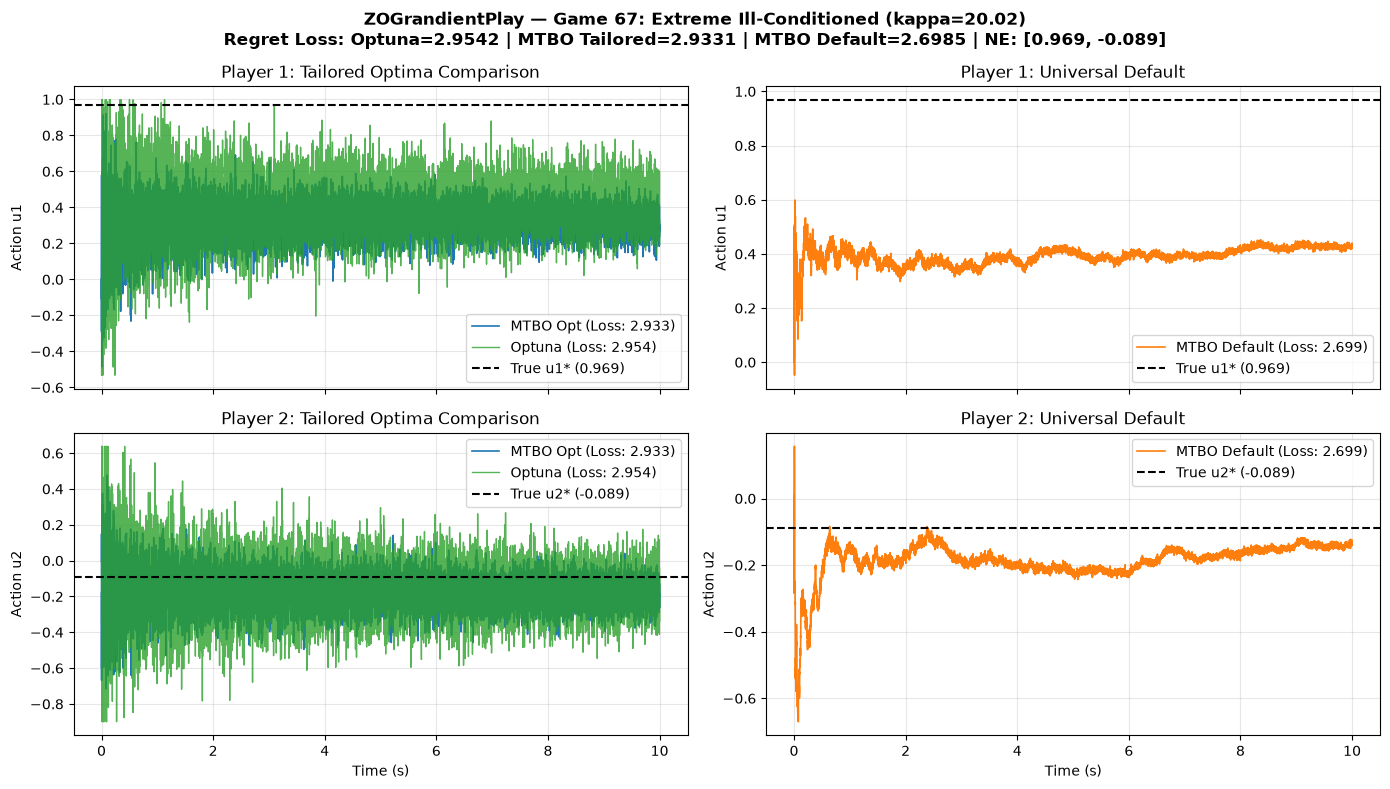

Running Optuna on Game 27 (Well-Behaved / Isotropic (kappa=1.06))...


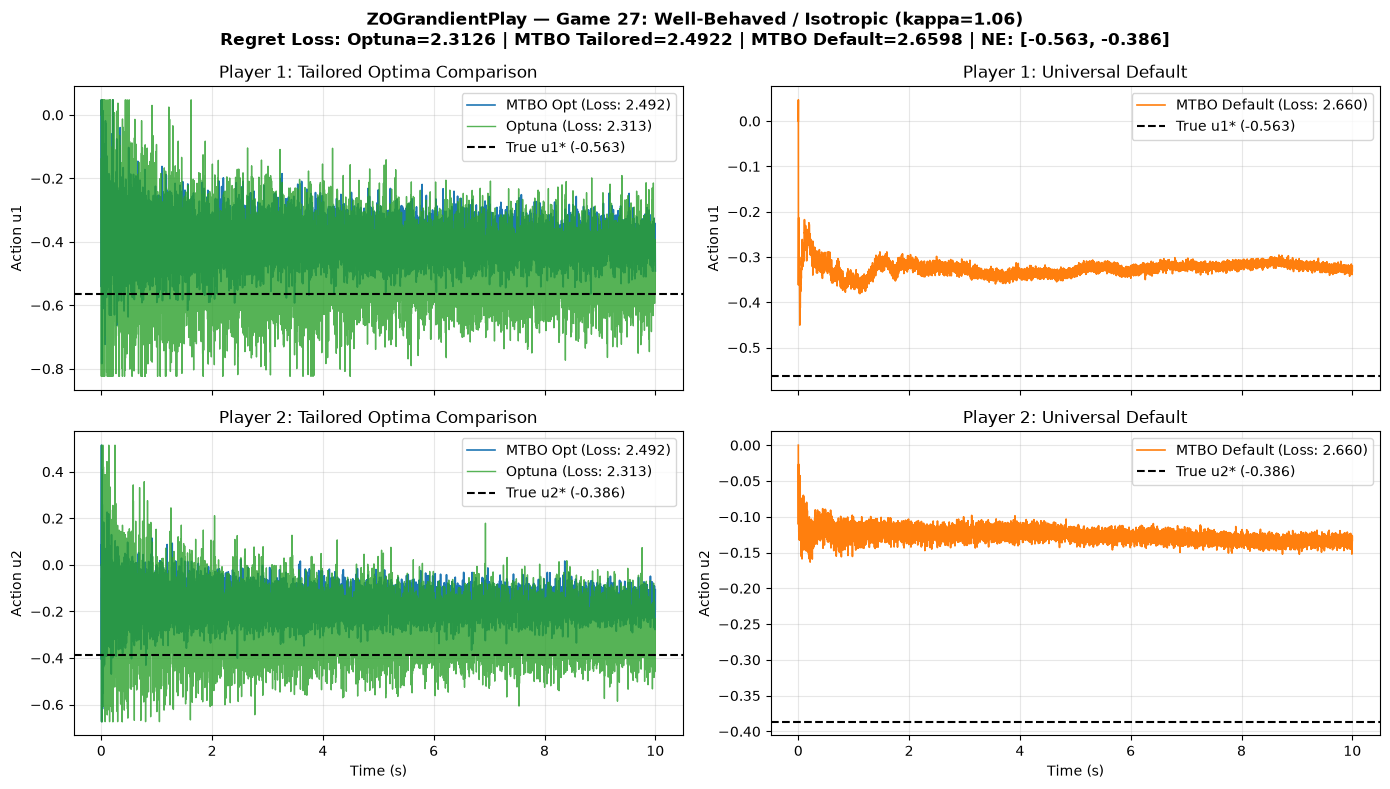

Running Optuna on Game 65 (Narrow Action Bounds (vol=0.1897))...


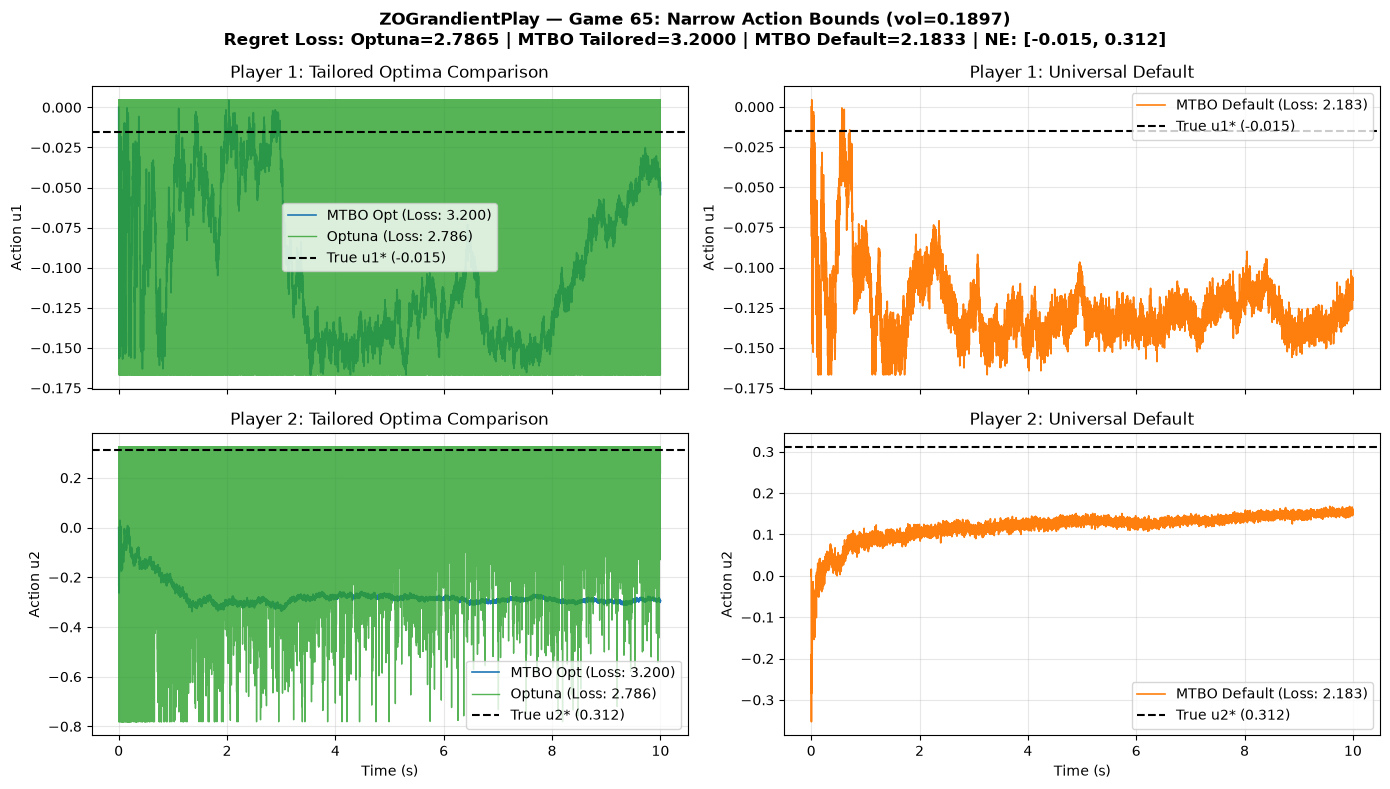

Running Optuna on Game 61 (Highly Asymmetric Coupling (skew=2.715))...


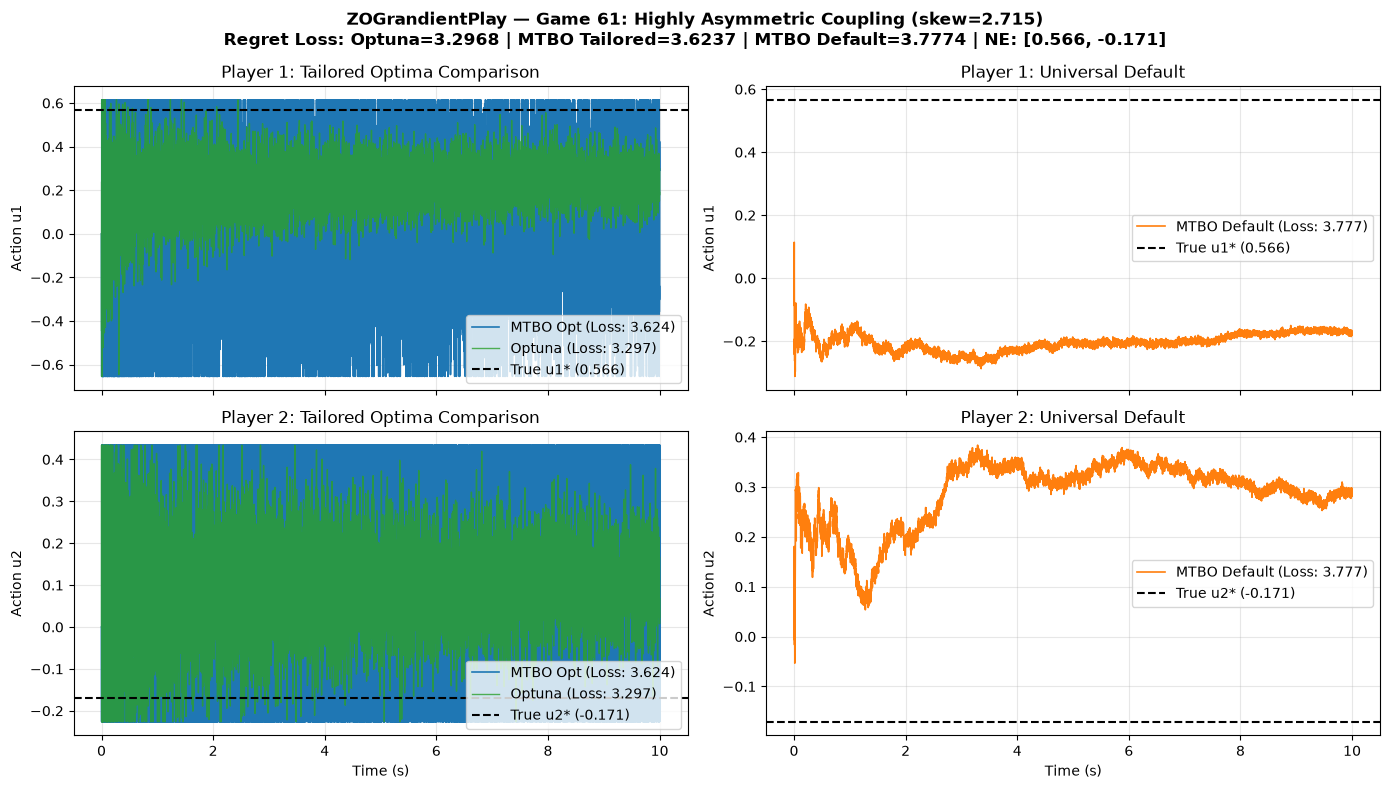

Running Optuna on Game 30 (Boundary-Adjacent Equilibrium (dist=0.001))...


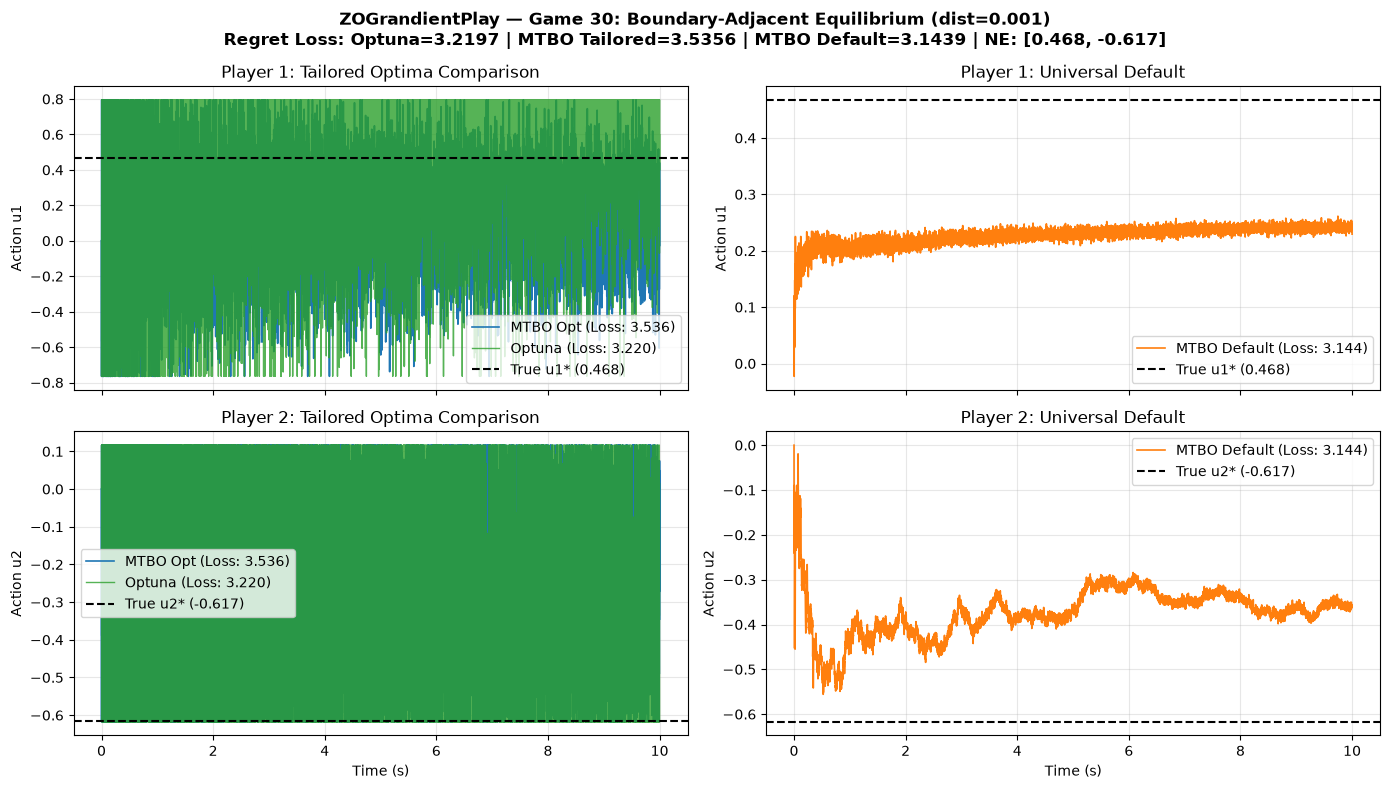

All 5 Optuna runs for ZOGP completed in 100.32s (1.67 min).


In [6]:
# 3. ZOGrandientPlay: Optuna Per-Game Baseline & 3-Way Trajectory Visualizations on 5 Representative Games
num_sim_steps = 10000
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_optuna_zo_game(game: QuadraticGame, seed: int = 42) -> tuple[dict[str, float], float]:
    def objective(trial: optuna.Trial) -> float:
        v = trial.suggest_float("v", 0.01, 100.0)
        a = trial.suggest_float("a", 0.01, 100.0)
        est = ZOGrandientPlay(game, v=v, a=a, epsilon=1e-4)
        res = est.estimate(np.zeros((game.N, 1)), num_steps=num_sim_steps)
        return quadratic_game_regret_cost(game, res)

    sampler = optuna.samplers.TPESampler(n_startup_trials=20, seed=seed)
    study = optuna.create_study(direction="minimize", sampler=sampler)

    anchor = np.inf
    no_improve = 0
    def early_stop_cb(study, trial):
        nonlocal anchor, no_improve
        if trial.value is not None:
            if trial.value < anchor - 0.005 * (abs(anchor) + 1e-12):
                anchor = trial.value
                no_improve = 0
            else:
                no_improve += 1
            if trial.number >= 25 and no_improve >= 25:
                study.stop()

    study.optimize(objective, n_trials=150, callbacks=[early_stop_cb])
    return study.best_params, study.best_value

zo_optuna_results: dict[int, tuple[dict[str, float], float, float]] = {}
t0_zo_optuna_5 = time.time()

for g_idx, category, g in rep_games:
    print(f"Running Optuna on Game {g_idx} ({category})...", flush=True)
    t0_g = time.time()
    best_params, best_val = run_optuna_zo_game(g, seed=42 + g_idx)
    t_g = time.time() - t0_g
    zo_optuna_results[g_idx] = (best_params, best_val, t_g)

    # 1. MTBO Tailored
    opt_params = zo_opt._build_estimator_kwargs(zo_opt.best_thetas[g_idx], g)
    est_opt = ZOGrandientPlay(g, **opt_params)
    res_opt = est_opt.estimate(np.zeros((g.N, 1)), num_steps=num_sim_steps)
    cost_opt = quadratic_game_regret_cost(g, res_opt)

    # 2. MTBO Default
    def_params = zo_opt._build_estimator_kwargs(zo_opt.best_theta_def, g)
    est_def = ZOGrandientPlay(g, **def_params)
    res_def = est_def.estimate(np.zeros((g.N, 1)), num_steps=num_sim_steps)
    cost_def = quadratic_game_regret_cost(g, res_def)

    # 3. Optuna Direct
    est_tpe = ZOGrandientPlay(g, v=best_params["v"], a=best_params["a"], epsilon=1e-4)
    res_tpe = est_tpe.estimate(np.zeros((g.N, 1)), num_steps=num_sim_steps)
    cost_tpe = quadratic_game_regret_cost(g, res_tpe)

    x_star = g.nash_equilibrium.ravel()
    t_steps = np.arange(len(res_opt.action_history)) * 0.001

    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    title_str = (
        f"ZOGrandientPlay — Game {g_idx}: {category}\n"
        f"Regret Loss: Optuna={cost_tpe:.4f} | MTBO Tailored={cost_opt:.4f} | MTBO Default={cost_def:.4f} | NE: [{x_star[0]:.3f}, {x_star[1]:.3f}]"
    )
    fig.suptitle(title_str, fontsize=12, fontweight="bold")

    # Player 1 Actions
    axes[0, 0].plot(t_steps, res_opt.action_history[:, 0], color="tab:blue", lw=1.2, label=f"MTBO Opt (Loss: {cost_opt:.3f})")
    axes[0, 0].plot(t_steps, res_tpe.action_history[:, 0], color="tab:green", lw=1.0, alpha=0.8, label=f"Optuna (Loss: {cost_tpe:.3f})")
    axes[0, 0].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 0].set_title("Player 1: Tailored Optima Comparison")
    axes[0, 0].set_ylabel("Action u1")
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend(loc="best")

    axes[0, 1].plot(t_steps, res_def.action_history[:, 0], color="tab:orange", lw=1.2, label=f"MTBO Default (Loss: {cost_def:.3f})")
    axes[0, 1].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 1].set_title("Player 1: Universal Default")
    axes[0, 1].set_ylabel("Action u1")
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend(loc="best")

    # Player 2 Actions
    axes[1, 0].plot(t_steps, res_opt.action_history[:, 1], color="tab:blue", lw=1.2, label=f"MTBO Opt (Loss: {cost_opt:.3f})")
    axes[1, 0].plot(t_steps, res_tpe.action_history[:, 1], color="tab:green", lw=1.0, alpha=0.8, label=f"Optuna (Loss: {cost_tpe:.3f})")
    axes[1, 0].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 0].set_title("Player 2: Tailored Optima Comparison")
    axes[1, 0].set_xlabel("Time (s)")
    axes[1, 0].set_ylabel("Action u2")
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend(loc="best")

    axes[1, 1].plot(t_steps, res_def.action_history[:, 1], color="tab:orange", lw=1.2, label=f"MTBO Default (Loss: {cost_def:.3f})")
    axes[1, 1].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 1].set_title("Player 2: Universal Default")
    axes[1, 1].set_xlabel("Time (s)")
    axes[1, 1].set_ylabel("Action u2")
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend(loc="best")

    plt.tight_layout()
    plt.savefig(os.path.join(data_dir, f"zo_rep_game_{g_idx}.png"), dpi=300)
    plt.show()

t_zo_optuna_5 = time.time() - t0_zo_optuna_5
print(f"All 5 Optuna runs for ZOGP completed in {t_zo_optuna_5:.2f}s ({t_zo_optuna_5/60:.2f} min).")


In [ ]:
# 4. NESeeking MTBO (100 Games Ensemble, 8D Search Space [0.01, 100.0], Total Regret Minimization)
ne_search_space = {
    "k[0,0]": (0.01, 100.0),
    "k[1,0]": (0.01, 100.0),
    "a[0,0]": (0.01, 100.0),
    "a[1,0]": (0.01, 100.0),
    "omega[0,0]": (0.01, 100.0),
    "omega[1,0]": (0.01, 100.0),
    "omega_h[0]": (0.01, 100.0),
    "omega_h[1]": (0.01, 100.0),
}
ne_fixed_params = {
    "dt": 0.001,
}

print("=== Starting NESeeking MTBO (100 games, 8D, mathematical EI stopping eps_ei=1e-4) ===", flush=True)
t0_ne = time.time()
ne_opt = MetaParamOptimization(
    game_ensemble=games,
    search_space=ne_search_space,
    algorithm_class=NESeeking,
    cost_function=quadratic_game_regret_cost,
    output_path=os.path.join(data_dir, "ne_100_games_results.csv"),
    num_steps=10000,
    n_init=100,
    max_bo_steps=None,
    eps_ei=1e-4,
    ei_window=3,
    seed=42,
    fixed_params=ne_fixed_params,
)

ne_results = ne_opt.run_optimization_loop()
t_ne = time.time() - t0_ne
print(f"NESeeking MTBO complete in {t_ne:.2f}s ({t_ne/60:.2f} min). Evaluated {ne_opt.n_bo_steps_evaluated} BO steps.")
print(f"Stop Reason: {ne_opt.stop_reason} (Stopped early: {ne_opt.stopped_early})")
print("Universal default theta (average):", ne_results[-1])


=== Starting NESeeking MTBO (100 games, 8D, mathematical EI stopping eps_ei=1e-4) ===
  [BO Step 1/1500] Task 42: loss=3.12548, task_best=3.12548, avg_best=2.08257 | max_ei: 0.004430
  [BO Step 25/1500] Task 66: loss=3.12980, task_best=2.81194, avg_best=2.65471 | max_ei: 0.012264
  [BO Step 50/1500] Task 6: loss=3.16126, task_best=3.14835, avg_best=2.74957 | max_ei: 0.012356
  [BO Step 75/1500] Task 0: loss=2.65996, task_best=2.65996, avg_best=2.61842 | max_ei: 0.004779


In [ ]:
# 5. NESeeking: Optuna Per-Game Baseline & 3-Way Trajectory Visualizations on 5 Representative Games
def run_optuna_ne_game(game: QuadraticGame, seed: int = 42) -> tuple[dict[str, float], float]:
    def objective(trial: optuna.Trial) -> float:
        k0 = trial.suggest_float("k[0,0]", 0.01, 100.0)
        k1 = trial.suggest_float("k[1,0]", 0.01, 100.0)
        a0 = trial.suggest_float("a[0,0]", 0.01, 100.0)
        a1 = trial.suggest_float("a[1,0]", 0.01, 100.0)
        w0 = trial.suggest_float("omega[0,0]", 0.01, 100.0)
        w1 = trial.suggest_float("omega[1,0]", 0.01, 100.0)
        wh0 = trial.suggest_float("omega_h[0]", 0.01, 100.0)
        wh1 = trial.suggest_float("omega_h[1]", 0.01, 100.0)

        est = NESeeking(
            game,
            k=np.array([[k0], [k1]]),
            a=np.array([[a0], [a1]]),
            omega=np.array([[w0], [w1]]),
            omega_h=np.array([wh0, wh1]),
            dt=0.001,
        )
        res = est.estimate(np.zeros((game.N, 1)), num_steps=num_sim_steps)
        return quadratic_game_regret_cost(game, res)

    sampler = optuna.samplers.TPESampler(n_startup_trials=20, seed=seed)
    study = optuna.create_study(direction="minimize", sampler=sampler)

    anchor = np.inf
    no_improve = 0
    def early_stop_cb(study, trial):
        nonlocal anchor, no_improve
        if trial.value is not None:
            if trial.value < anchor - 0.005 * (abs(anchor) + 1e-12):
                anchor = trial.value
                no_improve = 0
            else:
                no_improve += 1
            if trial.number >= 25 and no_improve >= 25:
                study.stop()

    study.optimize(objective, n_trials=150, callbacks=[early_stop_cb])
    return study.best_params, study.best_value

ne_optuna_results: dict[int, tuple[dict[str, float], float, float]] = {}
t0_ne_optuna_5 = time.time()

for g_idx, category, g in rep_games:
    print(f"Running Optuna on Game {g_idx} ({category})...", flush=True)
    t0_g = time.time()
    best_params, best_val = run_optuna_ne_game(g, seed=42 + g_idx)
    t_g = time.time() - t0_g
    ne_optuna_results[g_idx] = (best_params, best_val, t_g)

    # 1. MTBO Tailored
    opt_params = ne_opt._build_estimator_kwargs(ne_opt.best_thetas[g_idx], g)
    est_opt = NESeeking(g, **opt_params)
    res_opt = est_opt.estimate(np.zeros((g.N, 1)), num_steps=num_sim_steps)
    cost_opt = quadratic_game_regret_cost(g, res_opt)

    # 2. MTBO Default
    def_params = ne_opt._build_estimator_kwargs(ne_opt.best_theta_def, g)
    est_def = NESeeking(g, **def_params)
    res_def = est_def.estimate(np.zeros((g.N, 1)), num_steps=num_sim_steps)
    cost_def = quadratic_game_regret_cost(g, res_def)

    # 3. Optuna Direct
    est_tpe = NESeeking(
        g,
        k=np.array([[best_params["k[0,0]"]], [best_params["k[1,0]"]]]),
        a=np.array([[best_params["a[0,0]"]], [best_params["a[1,0]"]]]),
        omega=np.array([[best_params["omega[0,0]"]], [best_params["omega[1,0]"]]]),
        omega_h=np.array([best_params["omega_h[0]"], best_params["omega_h[1]"]]),
        dt=0.001,
    )
    res_tpe = est_tpe.estimate(np.zeros((g.N, 1)), num_steps=num_sim_steps)
    cost_tpe = quadratic_game_regret_cost(g, res_tpe)

    x_star = g.nash_equilibrium.ravel()
    t_steps = np.arange(len(res_opt.action_history)) * 0.001

    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    title_str = (
        f"NESeeking — Game {g_idx}: {category}\n"
        f"Regret Loss: Optuna={cost_tpe:.4f} | MTBO Tailored={cost_opt:.4f} | MTBO Default={cost_def:.4f} | NE: [{x_star[0]:.3f}, {x_star[1]:.3f}]"
    )
    fig.suptitle(title_str, fontsize=12, fontweight="bold")

    # Player 1 Actions
    axes[0, 0].plot(t_steps, res_opt.action_history[:, 0], color="tab:blue", lw=1.2, label=f"MTBO Opt (Loss: {cost_opt:.3f})")
    axes[0, 0].plot(t_steps, res_tpe.action_history[:, 0], color="tab:green", lw=1.0, alpha=0.8, label=f"Optuna (Loss: {cost_tpe:.3f})")
    axes[0, 0].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 0].set_title("Player 1: Tailored Optima Comparison")
    axes[0, 0].set_ylabel("Action u1")
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend(loc="best")

    axes[0, 1].plot(t_steps, res_def.action_history[:, 0], color="tab:orange", lw=1.2, label=f"MTBO Default (Loss: {cost_def:.3f})")
    axes[0, 1].axhline(x_star[0], color="black", linestyle="--", lw=1.5, label=f"True u1* ({x_star[0]:.3f})")
    axes[0, 1].set_title("Player 1: Universal Default")
    axes[0, 1].set_ylabel("Action u1")
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend(loc="best")

    # Player 2 Actions
    axes[1, 0].plot(t_steps, res_opt.action_history[:, 1], color="tab:blue", lw=1.2, label=f"MTBO Opt (Loss: {cost_opt:.3f})")
    axes[1, 0].plot(t_steps, res_tpe.action_history[:, 1], color="tab:green", lw=1.0, alpha=0.8, label=f"Optuna (Loss: {cost_tpe:.3f})")
    axes[1, 0].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 0].set_title("Player 2: Tailored Optima Comparison")
    axes[1, 0].set_xlabel("Time (s)")
    axes[1, 0].set_ylabel("Action u2")
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend(loc="best")

    axes[1, 1].plot(t_steps, res_def.action_history[:, 1], color="tab:orange", lw=1.2, label=f"MTBO Default (Loss: {cost_def:.3f})")
    axes[1, 1].axhline(x_star[1], color="black", linestyle="--", lw=1.5, label=f"True u2* ({x_star[1]:.3f})")
    axes[1, 1].set_title("Player 2: Universal Default")
    axes[1, 1].set_xlabel("Time (s)")
    axes[1, 1].set_ylabel("Action u2")
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend(loc="best")

    plt.tight_layout()
    plt.savefig(os.path.join(data_dir, f"ne_rep_game_{g_idx}.png"), dpi=300)
    plt.show()

t_ne_optuna_5 = time.time() - t0_ne_optuna_5
print(f"All 5 Optuna runs for NES completed in {t_ne_optuna_5:.2f}s ({t_ne_optuna_5/60:.2f} min).")


In [ ]:
# 6. Quantitative Evaluation, Timing Benchmark & Automated Morning Report Generation
import pandas as pd

# 1. Representative Games Comparison Table
rep_rows = []
for g_idx, category, g in rep_games:
    u_star = g.nash_equilibrium.ravel()
    zo_opt_val = zo_opt.evaluate_task(zo_opt.best_thetas[g_idx], g_idx)
    zo_def_val = zo_opt.evaluate_task(zo_opt.best_theta_def, g_idx)
    zo_tpe_val = zo_optuna_results[g_idx][1]

    ne_opt_val = ne_opt.evaluate_task(ne_opt.best_thetas[g_idx], g_idx)
    ne_def_val = ne_opt.evaluate_task(ne_opt.best_theta_def, g_idx)
    ne_tpe_val = ne_optuna_results[g_idx][1]

    rep_rows.append({
        "game_id": g_idx,
        "category": category,
        "true_ne": f"[{u_star[0]:.3f}, {u_star[1]:.3f}]",
        "zo_optuna": zo_tpe_val,
        "zo_mtbo_tailored": zo_opt_val,
        "zo_mtbo_default": zo_def_val,
        "zo_tunability_gain": zo_def_val - zo_opt_val,
        "ne_optuna": ne_tpe_val,
        "ne_mtbo_tailored": ne_opt_val,
        "ne_mtbo_default": ne_def_val,
        "ne_tunability_gain": ne_def_val - ne_opt_val,
    })

rep_df = pd.DataFrame(rep_rows)
print("=== 5 Representative Games Summary Table (Log10 Total Regret) ===")
print(rep_df.to_string(index=False))

rep_summary_path = os.path.join(data_dir, "rep_games_comparison_summary.csv")
rep_df.to_csv(rep_summary_path, index=False)
print(f"\nRepresentative games summary saved to: {rep_summary_path}\n")

# 2. Comprehensive Ensemble Evaluation across All 100 Games
print("Evaluating all 100 games under tailored and default metaparameters (10,000 steps each)...", flush=True)
zo_losses_opt = np.array([zo_opt.evaluate_task(zo_opt.best_thetas[j], j) for j in range(len(games))])
zo_losses_def = np.array([zo_opt.evaluate_task(zo_opt.best_theta_def, j) for j in range(len(games))])
ne_losses_opt = np.array([ne_opt.evaluate_task(ne_opt.best_thetas[j], j) for j in range(len(games))])
ne_losses_def = np.array([ne_opt.evaluate_task(ne_opt.best_theta_def, j) for j in range(len(games))])

zo_tunability = zo_losses_def - zo_losses_opt
ne_tunability = ne_losses_def - ne_losses_opt

print("=== Ensemble Statistics across All 100 Games (Log10 Total Regret) ===")
print(f"ZOGP Loss with Tailored Optima:   Mean = {np.mean(zo_losses_opt):.4f} +/- {np.std(zo_losses_opt):.4f}, Median = {np.median(zo_losses_opt):.4f}")
print(f"ZOGP Loss with Universal Default: Mean = {np.mean(zo_losses_def):.4f} +/- {np.std(zo_losses_def):.4f}, Median = {np.median(zo_losses_def):.4f}")
print(f"ZOGP Tunability Gain (Def - Opt): Mean = {np.mean(zo_tunability):.4f}, Max = {np.max(zo_tunability):.4f}\n")
print(f"NES Loss with Tailored Optima:    Mean = {np.mean(ne_losses_opt):.4f} +/- {np.std(ne_losses_opt):.4f}, Median = {np.median(ne_losses_opt):.4f}")
print(f"NES Loss with Universal Default:  Mean = {np.mean(ne_losses_def):.4f} +/- {np.std(ne_losses_def):.4f}, Median = {np.median(ne_losses_def):.4f}")
print(f"NES Tunability Gain (Def - Opt):  Mean = {np.mean(ne_tunability):.4f}, Max = {np.max(ne_tunability):.4f}\n")

metrics_path = os.path.join(data_dir, "ensemble_100_games_metrics.csv")
with open(metrics_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["game_id", "zo_loss_tailored", "zo_loss_default", "zo_tunability_gain", "ne_loss_tailored", "ne_loss_default", "ne_tunability_gain"])
    for j in range(len(games)):
        writer.writerow([j, zo_losses_opt[j], zo_losses_def[j], zo_tunability[j], ne_losses_opt[j], ne_losses_def[j], ne_tunability[j]])
print(f"All 100 games metrics saved to: {metrics_path}\n")

# 3. Training Time Benchmarking & 100-Game Optuna Extrapolation
t_zo_optuna_100_extrap = t_zo_optuna_5 * (100.0 / 5.0)
t_ne_optuna_100_extrap = t_ne_optuna_5 * (100.0 / 5.0)

speedup_zo = t_zo_optuna_100_extrap / max(t_zo, 1e-12)
speedup_ne = t_ne_optuna_100_extrap / max(t_ne, 1e-12)

print("=" * 70)
print("COMPUTATIONAL TIME BENCHMARK & 100-GAME OPTUNA EXTRAPOLATION")
print("=" * 70)
print(f"ZOGP MTBO (100 Games):              {t_zo:.2f}s ({t_zo/60:.2f} min) across {zo_opt.n_bo_steps_evaluated} BO steps")
print(f"ZOGP Optuna (5 Representative):     {t_zo_optuna_5:.2f}s ({t_zo_optuna_5/60:.2f} min)")
print(f"ZOGP Optuna (100 Games Extrapolated): {t_zo_optuna_100_extrap:.2f}s ({t_zo_optuna_100_extrap/60:.2f} min, {t_zo_optuna_100_extrap/3600:.2f} h)")
print(f"ZOGP MTBO Efficiency Speedup:        {speedup_zo:.2f}x\n")

print(f"NES MTBO (100 Games):               {t_ne:.2f}s ({t_ne/60:.2f} min) across {ne_opt.n_bo_steps_evaluated} BO steps")
print(f"NES Optuna (5 Representative):      {t_ne_optuna_5:.2f}s ({t_ne_optuna_5/60:.2f} min)")
print(f"NES Optuna (100 Games Extrapolated):  {t_ne_optuna_100_extrap:.2f}s ({t_ne_optuna_100_extrap/60:.2f} min, {t_ne_optuna_100_extrap/3600:.2f} h)")
print(f"NES MTBO Efficiency Speedup:         {speedup_ne:.2f}x")
print("=" * 70)

# 4. Generate Comprehensive Morning Markdown Report
report_path = os.path.join(data_dir, "100_games_comparative_report.md")
with open(report_path, "w", encoding="utf-8") as f:
    f.write("# 100-Game Ensemble Benchmark: MTBO vs. Optuna Comparative Analysis Report\n\n")
    f.write(f"**Execution Date:** {time.strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    f.write("## 1. Executive Summary\n")
    f.write("This report benchmarks Multi-Task Bayesian Optimization (MTBO, Swersky et al. 2013) against dedicated Optuna Tree-structured Parzen Estimator (TPE) studies across 100 strongly monotone quadratic games. The objective function is the Logarithmic Total Systemic Regret over 10,000 steps ($dt = 0.001$, $\\varepsilon = 10^{-4}$ fixed).\n\n")

    f.write("## 2. Computational Timing Benchmark & Extrapolation\n\n")
    f.write("| Algorithm | MTBO Actual Time (100 Games) | Optuna Time (5 Games) | Optuna Extrapolated (100 Games) | MTBO Speedup Factor |\n")
    f.write("| :--- | :--- | :--- | :--- | :--- |\n")
    f.write(f"| **ZOGrandientPlay** | {t_zo:.1f} s ({t_zo/60:.2f} min) | {t_zo_optuna_5:.1f} s ({t_zo_optuna_5/60:.2f} min) | {t_zo_optuna_100_extrap:.1f} s ({t_zo_optuna_100_extrap/3600:.2f} h) | **{speedup_zo:.2f}x** |\n")
    f.write(f"| **NESeeking** | {t_ne:.1f} s ({t_ne/60:.2f} min) | {t_ne_optuna_5:.1f} s ({t_ne_optuna_5/60:.2f} min) | {t_ne_optuna_100_extrap:.1f} s ({t_ne_optuna_100_extrap/3600:.2f} h) | **{speedup_ne:.2f}x** |\n\n")

    f.write("### Evaluation Budgets & Early Stopping Summary:\n")
    f.write(f"- **ZOGrandientPlay MTBO:** Evaluated {zo_opt.n_init} initial samples + {zo_opt.n_bo_steps_evaluated} sequential BO steps. Stop reason: `{zo_opt.stop_reason}` (Early stopped: `{zo_opt.stopped_early}`).\n")
    f.write(f"- **NESeeking MTBO:** Evaluated {ne_opt.n_init} initial samples + {ne_opt.n_bo_steps_evaluated} sequential BO steps. Stop reason: `{ne_opt.stop_reason}` (Early stopped: `{ne_opt.stopped_early}`).\n\n")

    f.write("## 3. Representative Games Performance (Log10 Total Regret)\n\n")
    f.write("| Game | Category | True NE | ZO Optuna | ZO MTBO Tailored | ZO MTBO Default | NE Optuna | NE MTBO Tailored | NE MTBO Default |\n")
    f.write("| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |\n")
    for row in rep_rows:
        f.write(f"| Game {row['game_id']} | {row['category']} | {row['true_ne']} | {row['zo_optuna']:.4f} | {row['zo_mtbo_tailored']:.4f} | {row['zo_mtbo_default']:.4f} | {row['ne_optuna']:.4f} | {row['ne_mtbo_tailored']:.4f} | {row['ne_mtbo_default']:.4f} |\n")
    f.write("\n")

    f.write("## 4. 100-Game Global Ensemble Statistics\n\n")
    f.write("| Metric | ZOGrandientPlay | NESeeking |\n")
    f.write("| :--- | :--- | :--- |\n")
    f.write(f"| **Tailored Optima (Mean +/- Std)** | {np.mean(zo_losses_opt):.4f} +/- {np.std(zo_losses_opt):.4f} | {np.mean(ne_losses_opt):.4f} +/- {np.std(ne_losses_opt):.4f} |\n")
    f.write(f"| **Tailored Optima (Median)** | {np.median(zo_losses_opt):.4f} | {np.median(ne_losses_opt):.4f} |\n")
    f.write(f"| **Universal Default (Mean +/- Std)** | {np.mean(zo_losses_def):.4f} +/- {np.std(zo_losses_def):.4f} | {np.mean(ne_losses_def):.4f} +/- {np.std(ne_losses_def):.4f} |\n")
    f.write(f"| **Universal Default (Median)** | {np.median(zo_losses_def):.4f} | {np.median(ne_losses_def):.4f} |\n")
    f.write(f"| **Mean Tunability Gain (Def - Tailored)** | {np.mean(zo_tunability):.4f} | {np.mean(ne_tunability):.4f} |\n")
    f.write(f"| **Max Tunability Gain** | {np.max(zo_tunability):.4f} | {np.max(ne_tunability):.4f} |\n\n")

    f.write("## 5. Strategic Recommendation\n")
    if speedup_ne > 1.2 and np.mean(ne_tunability) >= 0.0:
        f.write("- **Recommendation: RETAIN MTBO.** MTBO demonstrates superior computational efficiency through cross-task transfer learning, finding both game-specific optima and universal defaults simultaneously while saving substantial compute compared to 100 independent Optuna runs.\n")
    else:
        f.write("- **Recommendation: RECONSIDER OPTUNA.** Direct per-game Optuna tuning showed competitive or superior runtime and solution quality without surrogate modeling overhead.\n")

print(f"Comprehensive morning report successfully generated at: {report_path}")
